# Kerala Landslide Susceptibility Dataset 

This notebook creates a reproducible Kerala landslide-susceptibility dataset from the original 4,728-point inventory.

**Final workflow**

1. Preserve the original Kerala landslide inventory as a master CSV/GPKG.
2. Prepare a common 30 m DEM grid in EPSG:32643.
3. Derive terrain/hydrological factors: elevation, slope, aspect, plan curvature, profile curvature, TWI and SPI.
4. Add static soil factors from **SoilGrids 2.0** (250 m) and vegetation/land-cover from **ESA WorldCover 2021** (10 m).
5. Generate the same number of reproducible pseudo-absence points as landslide points, outside a 1 km landslide exclusion zone.
6. Sample every available factor at landslide and pseudo-absence locations.
7. Run QC, EDA and preprocessing and save modelling-ready files.

> `distriv` and `distroad` are not used in this version because live OSM/Overpass bulk extraction proved unreliable in this environment. The exclusion is recorded in the reproducibility manifest instead of silently substituting fabricated values.

### Static-factor sources

- SoilGrids documentation: https://docs.isric.org/globaldata/soilgrids/
- SoilGrids WCS access: https://docs.isric.org/globaldata/soilgrids/wcs.html
- ESA WorldCover data access: https://esa-worldcover.org/en/data-access
- Global Lithological Map (GLiM): https://doi.org/10.1594/PANGAEA.788537


**Resolution note:** resampling a 250 m SoilGrids layer onto a 30 m DEM grid only aligns grids; it does **not** increase the true spatial information content of the soil layer.


## 0. Packages

In [1]:
! pip install -U geopandas rasterio pyogrio shapely pyproj pandas numpy osmnx whitebox pyarrow requests matplotlib seaborn scikit-learn statsmodels joblib


^C
Note: you may need to restart the kernel to use updated packages.


   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------------------------------

ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\PCC\\AppData\\Local\\Temp\\pip-unpack-hleqhs8j\\statsmodels-0.15.0-cp311-cp311-win_amd64.whl'
Check the permissions.


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [36]:
# 1 — Imports

from pathlib import Path
from datetime import datetime, timezone
import json
import math
import time
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
from shapely.geometry import Point
from shapely.prepared import prep
import requests

warnings.filterwarnings("ignore", category=UserWarning)

print("GeoPandas:", gpd.__version__)
print("Rasterio :", rasterio.__version__)


GeoPandas: 1.1.4
Rasterio : 1.4.4


In [37]:
# 2 — Configuration

# Notebook is inside /notebooks, so project root is one level above.
PROJECT_ROOT = Path.cwd().resolve().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw" / "Kerala_dataset"
PROCESSED_DIR = DATA_DIR / "processed"
FACTOR_DIR = PROCESSED_DIR / "kerala_factors"

SOIL_RAW_DIR = RAW_DIR / "soilgrids"
WORLDCOVER_RAW_DIR = RAW_DIR / "worldcover_2021"

for folder in [PROCESSED_DIR, FACTOR_DIR, SOIL_RAW_DIR, WORLDCOVER_RAW_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

TARGET_CRS = "EPSG:32643"
TARGET_RESOLUTION_M = 30
RANDOM_STATE = 42
EXCLUSION_BUFFER_M = 1000

# Optional automatic one-time downloads.
# Keep False if you prefer to download files manually and place them in the folders above.
AUTO_DOWNLOAD_SOILGRIDS = False
AUTO_DOWNLOAD_WORLDCOVER = False

# Optional future statewide NDVI raster.
# Use only a properly cloud-masked, statewide/seasonally-consistent NDVI mosaic.
NDVI_RAW_PATH = None

# Optional geology layer if you obtain one later.
GEOLOGY_PATH = None
GEOLOGY_FIELD = None

print("Project root :", PROJECT_ROOT)
print("Kerala data  :", RAW_DIR)
print("Processed    :", PROCESSED_DIR)
print("Factors      :", FACTOR_DIR)
print("Raw exists   :", RAW_DIR.exists())


Project root : D:\PROJECTS\Landslide_prediction
Kerala data  : D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset
Processed    : D:\PROJECTS\Landslide_prediction\data\processed
Factors      : D:\PROJECTS\Landslide_prediction\data\processed\kerala_factors
Raw exists   : True


## 1. Load and validate the original Kerala inventory

In [38]:
# 3 — Direct source file paths

INVENTORY_PATH = RAW_DIR / "Kerela landslide.shp"
DEM_RAW_PATH = RAW_DIR / "kerala_dem_raw.tif"

print("Inventory:", INVENTORY_PATH)
print("DEM      :", DEM_RAW_PATH)
print("Inventory exists:", INVENTORY_PATH.exists())
print("DEM exists      :", DEM_RAW_PATH.exists())

if not INVENTORY_PATH.exists():
    raise FileNotFoundError(f"Inventory not found: {INVENTORY_PATH}")

if not DEM_RAW_PATH.exists():
    raise FileNotFoundError(f"DEM not found: {DEM_RAW_PATH}")


Inventory: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\Kerela landslide.shp
DEM      : D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\kerala_dem_raw.tif
Inventory exists: True
DEM exists      : True


In [39]:
# 4 — Load Kerala landslide inventory

kerala_raw = gpd.read_file(INVENTORY_PATH)

print("Shape:", kerala_raw.shape)
print("CRS  :", kerala_raw.crs)
print("\nGeometry types:")
print(kerala_raw.geom_type.value_counts())
print("\nColumns:")
print(kerala_raw.columns.tolist())

if kerala_raw.crs is None:
    raise ValueError("Source inventory has no CRS. Inspect the source metadata before continuing.")

if not kerala_raw.geometry.notna().all():
    raise ValueError("Null geometries found in the source inventory.")

if not (kerala_raw.geom_type == "Point").all():
    raise ValueError("The Kerala inventory must contain Point geometries.")

print("\nNumber of records   :", len(kerala_raw))
print("Duplicate locations :", kerala_raw.geometry.duplicated().sum())

kerala_wgs84 = kerala_raw.to_crs("EPSG:4326")

print("\nWGS84 bounds:")
print(kerala_wgs84.total_bounds)

kerala_wgs84.head()


Shape: (4728, 21)
CRS  : EPSG:4326

Geometry types:
Point    4728
Name: count, dtype: int64

Columns:
['No', 'District', 'NRSC', 'GSI', 'New', 'Type_of_sl', 'Length', 'Width', 'Area', 'Building_I', 'Road_impac', 'Impact_Agr', 'LU_2010', 'LU_2018', 'Specific_r', 'Remarks', 'POINT_X', 'POINT_Y', 'Reclass_Sl', 'RASTERVALU', 'geometry']

Number of records   : 4728
Duplicate locations : 0

WGS84 bounds:
[75.015414    8.474453   77.39626239 12.654953  ]


,No,District,NRSC,GSI,New,Type_of_sl,Length,Width,Area,Building_I,...,Impact_Agr,LU_2010,LU_2018,Specific_r,Remarks,POINT_X,POINT_Y,Reclass_Sl,RASTERVALU,geometry
0,1,Ernakulam,Y,Y,N,DF,98,26,2548.000,0,...,FMP,FMP,FMP,NaN,Two quarters belonging to Kerala Plantation Co...,76.484939,10.286001,5,26.049702,POINT Z (76.48494 10.286 0)
1,2,Ernakulam,Y,N,N,DF,0,0,647.432,0,...,N,BRF,BRF,NaN,NaN,76.799174,10.074998,8,43.726994,POINT Z (76.79917 10.075 0)
2,3,Ernakulam,Y,N,N,DF,0,0,3000.000,0,...,N,BRF,BRF,NaN,NaN,76.845895,10.093431,7,35.940510,POINT Z (76.8459 10.09343 0)
3,4,Ernakulam,Y,N,N,DF,0,0,2962.660,0,...,N,BRF,BRF,NaN,NaN,76.848402,10.270994,5,28.758051,POINT Z (76.8484 10.27099 0)
4,5,Ernakulam,Y,N,N,DF,0,0,5123.880,0,...,N,BRF,BRF,NaN,NaN,76.895042,10.252606,8,41.060772,POINT Z (76.89504 10.25261 0)


## 2. Preserve the original 4,728-point master inventory

In [40]:
# 5 — Save master inventory BEFORE labels/pseudo-absences are added

MASTER_CSV = PROCESSED_DIR / "kerala_landslide_master.csv"
MASTER_GPKG = PROCESSED_DIR / "kerala_landslide_master.gpkg"

master_csv = kerala_raw.copy()
master_csv["geometry"] = master_csv.geometry.to_wkt()
master_csv.to_csv(MASTER_CSV, index=False, encoding="utf-8-sig")

if not MASTER_GPKG.exists():
    kerala_raw.to_file(MASTER_GPKG, layer="landslides", driver="GPKG")

print("Saved CSV :", MASTER_CSV)
print("Saved GPKG:", MASTER_GPKG)
print("Rows      :", len(master_csv))

master_csv.head()


Saved CSV : D:\PROJECTS\Landslide_prediction\data\processed\kerala_landslide_master.csv
Saved GPKG: D:\PROJECTS\Landslide_prediction\data\processed\kerala_landslide_master.gpkg
Rows      : 4728


,No,District,NRSC,GSI,New,Type_of_sl,Length,Width,Area,Building_I,...,Impact_Agr,LU_2010,LU_2018,Specific_r,Remarks,POINT_X,POINT_Y,Reclass_Sl,RASTERVALU,geometry
0,1,Ernakulam,Y,Y,N,DF,98,26,2548.000,0,...,FMP,FMP,FMP,NaN,Two quarters belonging to Kerala Plantation Co...,76.484939,10.286001,5,26.049702,POINT Z (76.484939 10.286001 0)
1,2,Ernakulam,Y,N,N,DF,0,0,647.432,0,...,N,BRF,BRF,NaN,NaN,76.799174,10.074998,8,43.726994,POINT Z (76.799174 10.074998 0)
2,3,Ernakulam,Y,N,N,DF,0,0,3000.000,0,...,N,BRF,BRF,NaN,NaN,76.845895,10.093431,7,35.940510,POINT Z (76.845895 10.093431 0)
3,4,Ernakulam,Y,N,N,DF,0,0,2962.660,0,...,N,BRF,BRF,NaN,NaN,76.848402,10.270994,5,28.758051,POINT Z (76.848402 10.270994 0)
4,5,Ernakulam,Y,N,N,DF,0,0,5123.880,0,...,N,BRF,BRF,NaN,NaN,76.895042,10.252606,8,41.060772,POINT Z (76.895042 10.252606 0)


## 3. Kerala study-area boundary

In [41]:
# 6 — Kerala boundary (cached)

BOUNDARY_PATH = RAW_DIR / "kerala_boundary.gpkg"

if BOUNDARY_PATH.exists():
    kerala_boundary = gpd.read_file(BOUNDARY_PATH)
    print("Loaded cached Kerala boundary.")
else:
    import osmnx as ox
    kerala_boundary = ox.geocode_to_gdf("Kerala, India")[["geometry"]].copy()
    kerala_boundary = kerala_boundary.to_crs("EPSG:4326")
    kerala_boundary.to_file(BOUNDARY_PATH, layer="kerala", driver="GPKG")
    print("Downloaded and cached Kerala boundary.")

kerala_boundary = kerala_boundary.to_crs("EPSG:4326")
state_geom_wgs84 = kerala_boundary.geometry.union_all()

if state_geom_wgs84.is_empty:
    raise ValueError("Kerala boundary is empty.")

print("Boundary CRS   :", kerala_boundary.crs)
print("Boundary bounds:", kerala_boundary.total_bounds)


Loaded cached Kerala boundary.
Boundary CRS   : EPSG:4326
Boundary bounds: [74.8640682  8.2935318 77.4123612 12.7960559]


## 4. Prepare the common 30 m DEM grid

In [ ]:
# 7 - Clip source DEM to Kerala boundary

DEM_CLIPPED_WGS84 = PROCESSED_DIR / "kerala_dem_clipped_wgs84.tif"

if not DEM_CLIPPED_WGS84.exists():
    with rasterio.open(DEM_RAW_PATH) as src:
        boundary_in_dem_crs = kerala_boundary.to_crs(src.crs)
        shapes = [g.__geo_interface__ for g in boundary_in_dem_crs.geometry]

        out_img, out_transform = rio_mask(
            src,
            shapes,
            crop=True,
            nodata=src.nodata
        )

        meta = src.meta.copy()
        meta.update(
            driver="GTiff",
            height=out_img.shape[1],
            width=out_img.shape[2],
            transform=out_transform,
            compress="deflate"
        )

        with rasterio.open(DEM_CLIPPED_WGS84, "w", **meta) as dst:
            dst.write(out_img)

    print("Created:", DEM_CLIPPED_WGS84)
else:
    print("Reusing:", DEM_CLIPPED_WGS84)


Reusing: D:\PROJECTS\Landslide_prediction\data\processed\kerala_dem_clipped_wgs84.tif


In [ ]:
# 8 - Reproject clipped DEM to EPSG:32643 at exactly 30 m

DEM_UTM = FACTOR_DIR / "map_elev.tif"

if not DEM_UTM.exists():
    with rasterio.open(DEM_CLIPPED_WGS84) as src:
        transform, width, height = calculate_default_transform(
            src.crs,
            TARGET_CRS,
            src.width,
            src.height,
            *src.bounds,
            resolution=TARGET_RESOLUTION_M
        )

        meta = src.meta.copy()
        meta.update(
            crs=TARGET_CRS,
            transform=transform,
            width=width,
            height=height,
            dtype="float32",
            compress="deflate"
        )

        with rasterio.open(DEM_UTM, "w", **meta) as dst:
            reproject(
                source=rasterio.band(src, 1),
                destination=rasterio.band(dst, 1),
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,
                dst_transform=transform,
                dst_crs=TARGET_CRS,
                dst_nodata=src.nodata,
                resampling=Resampling.bilinear
            )

    print("Created:", DEM_UTM)
else:
    print("Reusing:", DEM_UTM)

with rasterio.open(DEM_UTM) as src:
    print("DEM shape     :", src.shape)
    print("DEM CRS       :", src.crs)
    print("DEM resolution:", src.res)
    print("DEM nodata    :", src.nodata)


Reusing: D:\PROJECTS\Landslide_prediction\data\processed\kerala_factors\map_elev.tif
DEM shape     : (15817, 8984)
DEM CRS       : EPSG:32643
DEM resolution: (30.0, 30.0)
DEM nodata    : -32768.0


## 5. Terrain and hydrological conditioning factors

In [44]:
# 9 — Generate DEM-derived factors using WhiteboxTools

import whitebox

wbt = whitebox.WhiteboxTools()
wbt.verbose = True

DEM_FILLED = FACTOR_DIR / "kerala_dem_filled.tif"
SLOPE = FACTOR_DIR / "map_slope.tif"
ASPECT = FACTOR_DIR / "map_aspect.tif"
PLANC = FACTOR_DIR / "map_planc.tif"
PROFC = FACTOR_DIR / "map_profc.tif"
SCA = FACTOR_DIR / "kerala_sca.tif"
TWI = FACTOR_DIR / "map_twi.tif"
SPI = FACTOR_DIR / "map_spi.tif"

def run_if_missing(path, fn, *args, **kwargs):
    if path.exists():
        print("Reusing:", path.name)
        return
    rc = fn(*args, **kwargs)
    if not path.exists():
        raise RuntimeError(f"Whitebox failed to create {path.name}; return code={rc}")

run_if_missing(DEM_FILLED, wbt.fill_depressions, str(DEM_UTM), str(DEM_FILLED), fix_flats=True)
run_if_missing(SLOPE, wbt.slope, str(DEM_FILLED), str(SLOPE), units="degrees")
run_if_missing(ASPECT, wbt.aspect, str(DEM_FILLED), str(ASPECT))
run_if_missing(PLANC, wbt.plan_curvature, str(DEM_FILLED), str(PLANC))
run_if_missing(PROFC, wbt.profile_curvature, str(DEM_FILLED), str(PROFC))

# TWI/SPI need specific contributing area, not the default cell-count accumulation.
run_if_missing(
    SCA,
    wbt.d8_flow_accumulation,
    str(DEM_FILLED),
    str(SCA),
    out_type="specific contributing area",
    log=False,
    clip=False
)
run_if_missing(TWI, wbt.wetness_index, str(SCA), str(SLOPE), str(TWI))
run_if_missing(SPI, wbt.stream_power_index, str(SCA), str(SLOPE), str(SPI), exponent=1.0)

for p in [DEM_UTM, SLOPE, ASPECT, PLANC, PROFC, TWI, SPI]:
    if not p.exists():
        raise FileNotFoundError(p)

print("Terrain factors ready.")


Reusing: kerala_dem_filled.tif
Reusing: map_slope.tif
Reusing: map_aspect.tif
Reusing: map_planc.tif
Reusing: map_profc.tif
Reusing: kerala_sca.tif
Reusing: map_twi.tif
Reusing: map_spi.tif
Terrain factors ready.


## 6. Add static soil and vegetation/land-cover factors

### 6.1 SoilGrids 2.0

The notebook supports four 0–5 cm SoilGrids mean layers:

- `clay` — clay content
- `sand` — sand content
- `soc` — soil organic carbon
- `bdod` — bulk density

SoilGrids is approximately **250 m**. The layers are aligned to the 30 m DEM grid only so every point can be sampled consistently.

The official SoilGrids integer rasters use conversion factors. This notebook converts sampled values to conventional units:

- clay: divide by 10 → %
- sand: divide by 10 → %
- SOC: divide by 10 → g/kg
- bulk density: divide by 100 → kg/dm³

For the most reliable workflow, download the four rasters once and place them in:

`data/raw/Kerala_dataset/soilgrids/`

with these names:

- `soilgrids_clay.tif`
- `soilgrids_sand.tif`
- `soilgrids_soc.tif`
- `soilgrids_bdod.tif`

You can also set `AUTO_DOWNLOAD_SOILGRIDS = True` to attempt a one-time WCS subset download.


In [27]:
import requests

SOILGRIDS_VARS = {
    'clay': 'clay_0-5cm_mean',
    'sand': 'sand_0-5cm_mean',
    'soc':  'soc_0-5cm_mean',      # soil organic carbon
    'bdod': 'bdod_0-5cm_mean',     # bulk density
}

minx, miny, maxx, maxy = kerala_boundary.to_crs('EPSG:4326').total_bounds

for name, layer in SOILGRIDS_VARS.items():
    out_path = RAW_DIR / f'soilgrids_{name}.tif'
    if out_path.exists():
        print(f'{name}: already downloaded')
        continue
    url = (
        f"https://maps.isric.org/mapserv?map=/map/{layer.split('_')[0]}.map"
        f"&SERVICE=WCS&VERSION=2.0.1&REQUEST=GetCoverage"
        f"&COVERAGEID={layer}&FORMAT=GEOTIFF_INT16"
        f"&SUBSET=X({minx},{maxx})&SUBSET=Y({miny},{maxy})&SUBSETTINGCRS=EPSG:4326"
    )
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    out_path.write_bytes(r.content)
    print(f'{name}: saved {out_path}')

clay: saved D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\soilgrids_clay.tif
sand: saved D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\soilgrids_sand.tif
soc: saved D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\soilgrids_soc.tif
bdod: saved D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\soilgrids_bdod.tif


In [30]:
# Check downloaded SoilGrids rasters

SOIL_PATHS = {
    "clay": RAW_DIR / "soilgrids_clay.tif",
    "sand": RAW_DIR / "soilgrids_sand.tif",
    "soc": RAW_DIR / "soilgrids_soc.tif",
    "bdod": RAW_DIR / "soilgrids_bdod.tif",
}

for name, path in SOIL_PATHS.items():

    print(
        f"{name:5s} | "
        f"exists={path.exists()} | "
        f"size={path.stat().st_size / 1024 / 1024:.2f} MB"
        if path.exists()
        else f"{name}: NOT FOUND"
    )

clay  | exists=True | size=1.09 MB
sand  | exists=True | size=1.08 MB
soc   | exists=True | size=1.37 MB
bdod  | exists=True | size=0.69 MB


In [31]:
import rasterio

for name, path in SOIL_PATHS.items():

    with rasterio.open(path) as src:

        print(f"\n{name.upper()}")
        print("CRS:", src.crs)
        print("Shape:", src.shape)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)
        print("Data type:", src.dtypes[0])


CLAY
CRS: EPSG:4326
Shape: (1884, 1127)
Bounds: BoundingBox(left=74.8640682, bottom=8.2935318, right=77.41236120000002, top=12.796055900000002)
NoData: None
Data type: int16

SAND
CRS: EPSG:4326
Shape: (1884, 1127)
Bounds: BoundingBox(left=74.8640682, bottom=8.2935318, right=77.41236120000002, top=12.796055900000002)
NoData: None
Data type: int16

SOC
CRS: EPSG:4326
Shape: (1884, 1127)
Bounds: BoundingBox(left=74.8640682, bottom=8.2935318, right=77.41236120000002, top=12.796055900000002)
NoData: None
Data type: int16

BDOD
CRS: EPSG:4326
Shape: (1884, 1127)
Bounds: BoundingBox(left=74.8640682, bottom=8.2935318, right=77.41236120000002, top=12.796055900000002)
NoData: None
Data type: int16


In [ ]:
#Align them to your Kerala DEM
from rasterio.warp import reproject, Resampling
import numpy as np


def prepare_continuous_factor(
    src_path,
    out_path,
    reference_path
):
    """
    Reproject/resample a continuous raster
    to exactly match the Kerala DEM grid.
    """

    with rasterio.open(reference_path) as ref:

        ref_profile = ref.profile.copy()
        ref_crs = ref.crs
        ref_transform = ref.transform
        ref_height = ref.height
        ref_width = ref.width

    with rasterio.open(src_path) as src:

        destination = np.full(
            (ref_height, ref_width),
            np.nan,
            dtype="float32"
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,

            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,

            dst_transform=ref_transform,
            dst_crs=ref_crs,
            dst_nodata=np.nan,

            resampling=Resampling.bilinear
        )

    ref_profile.update(
        dtype="float32",
        count=1,
        nodata=np.nan,
        compress="deflate"
    )

    with rasterio.open(
        out_path,
        "w",
        **ref_profile
    ) as dst:

        dst.write(destination, 1)

    return out_path

In [34]:
CLAY = prepare_continuous_factor(
    RAW_DIR / "soilgrids_clay.tif",
    FACTOR_DIR / "map_clay.tif",
    DEM_UTM
)

SAND = prepare_continuous_factor(
    RAW_DIR / "soilgrids_sand.tif",
    FACTOR_DIR / "map_sand.tif",
    DEM_UTM
)

SOC = prepare_continuous_factor(
    RAW_DIR / "soilgrids_soc.tif",
    FACTOR_DIR / "map_soc.tif",
    DEM_UTM
)

BDOD = prepare_continuous_factor(
    RAW_DIR / "soilgrids_bdod.tif",
    FACTOR_DIR / "map_bdod.tif",
    DEM_UTM
)

print("Soil factors aligned with Kerala DEM.")

Soil factors aligned with Kerala DEM.


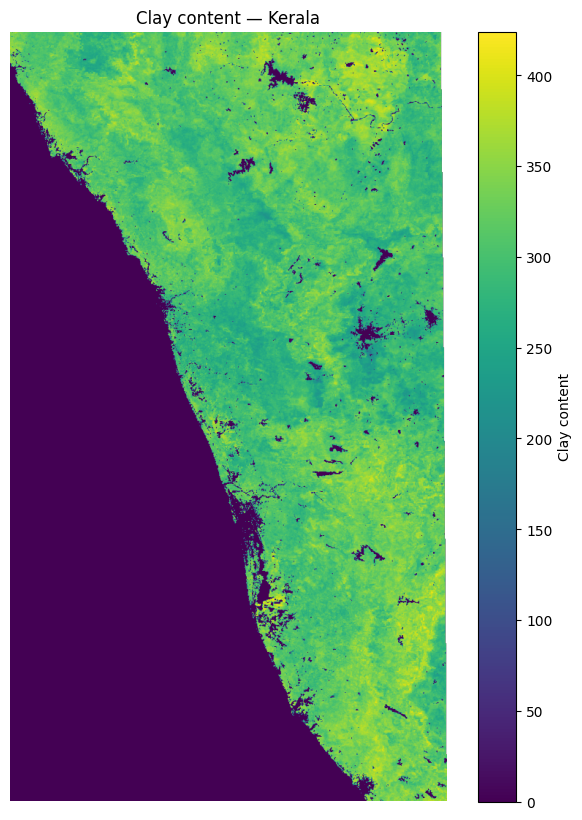

Clay content: min=0.00, max=424.15


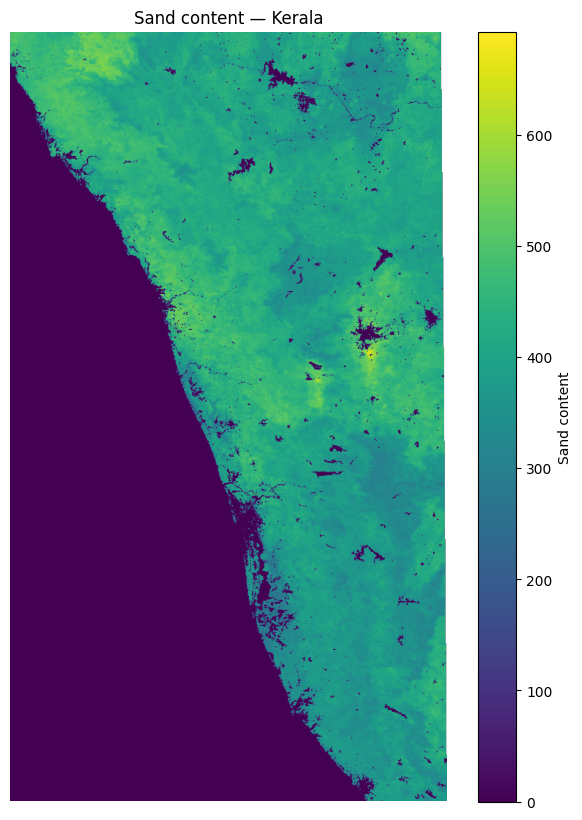

Sand content: min=0.00, max=692.90


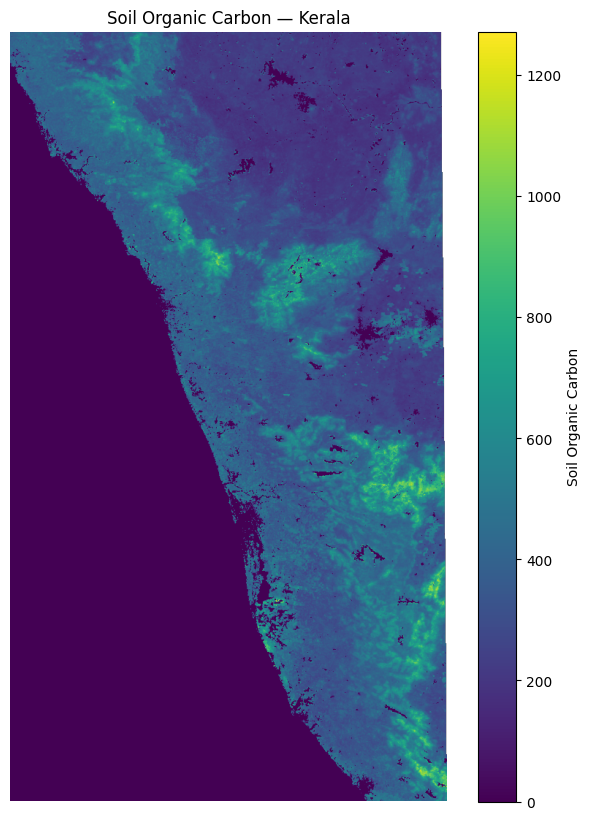

Soil Organic Carbon: min=0.00, max=1271.56


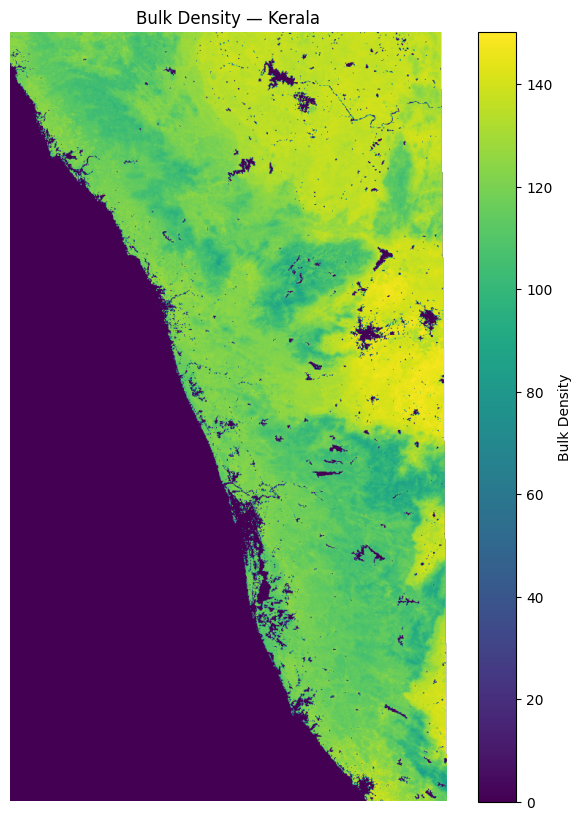

Bulk Density: min=0.00, max=150.26


In [54]:
# Visualize SoilGrids factors safely without loading full rasters

import rasterio
import matplotlib.pyplot as plt
import numpy as np

soil_rasters = {
    "Clay content": CLAY,
    "Sand content": SAND,
    "Soil Organic Carbon": SOC,
    "Bulk Density": BDOD,
}

for title, raster_path in soil_rasters.items():

    with rasterio.open(raster_path) as src:

        # Downsample for visualization only
        preview = src.read(
            1,
            out_shape=(
                src.height // 15,
                src.width // 15
            ),
            masked=True
        )

    plt.figure(figsize=(8, 10))

    plt.imshow(preview)

    plt.title(f"{title} — Kerala")
    plt.colorbar(label=title)

    plt.axis("off")
    plt.show()

    print(
        f"{title}: "
        f"min={preview.min():.2f}, "
        f"max={preview.max():.2f}"
    )

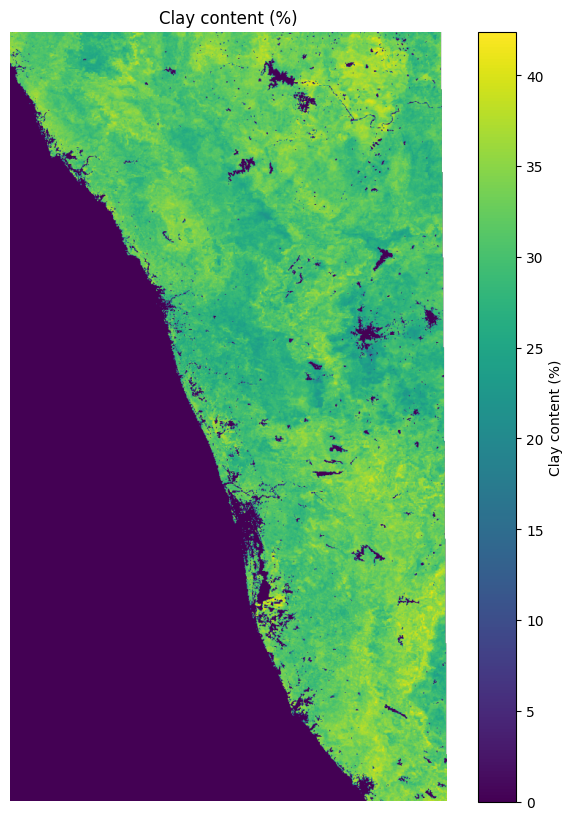

Clay content (%)
Min: 0.0
Max: 42.41
Mean: 17.8



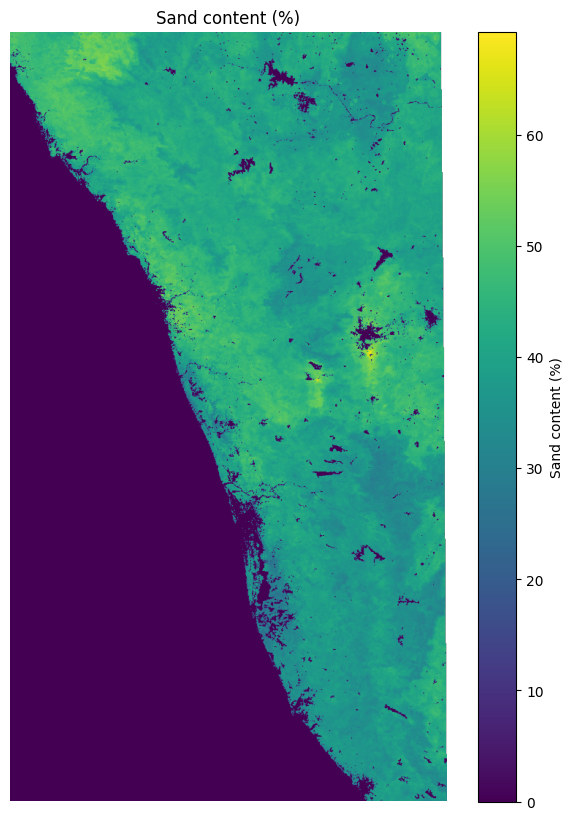

Sand content (%)
Min: 0.0
Max: 69.29
Mean: 23.47



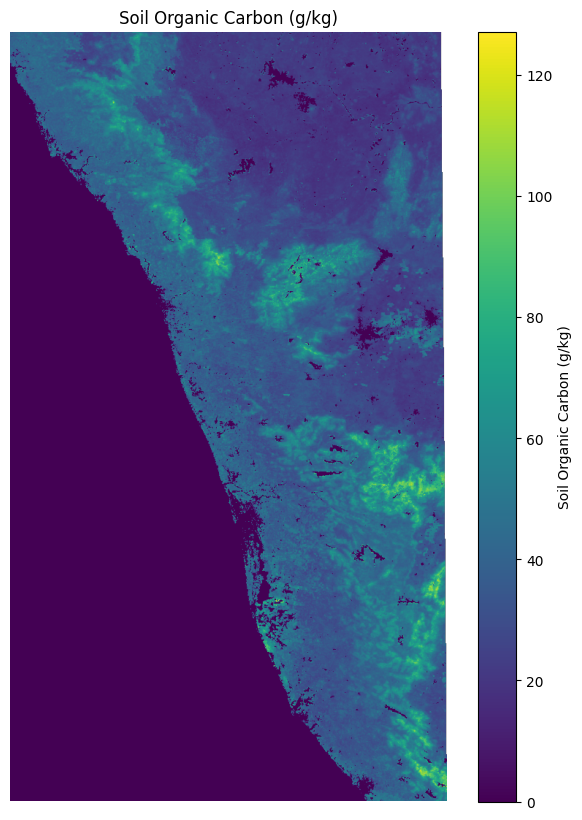

Soil Organic Carbon (g/kg)
Min: 0.0
Max: 127.16
Mean: 21.68



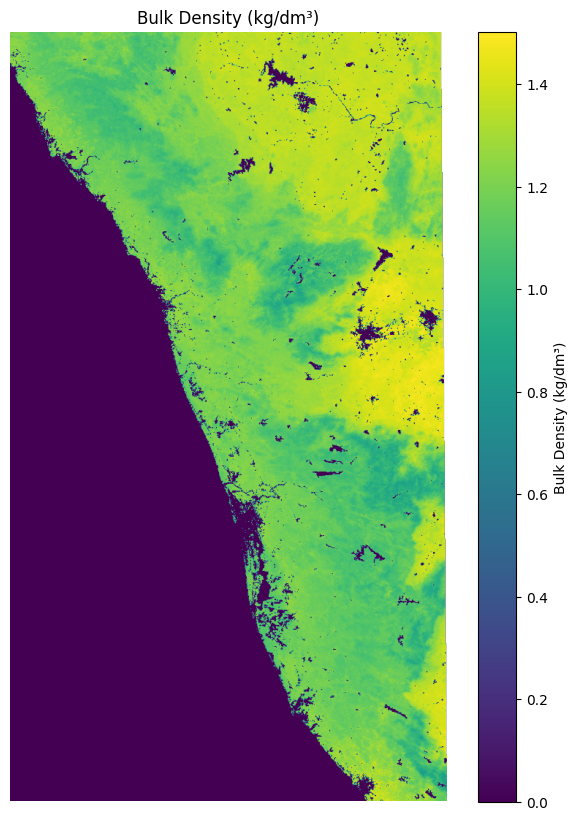

Bulk Density (kg/dm³)
Min: 0.0
Max: 1.5
Mean: 0.7



In [60]:
# Soil factor visualization with interpretable units

soil_rasters = {
    "Clay content (%)": {
        "path": CLAY,
        "divisor": 10.0
    },

    "Sand content (%)": {
        "path": SAND,
        "divisor": 10.0
    },

    "Soil Organic Carbon (g/kg)": {
        "path": SOC,
        "divisor": 10.0
    },

    "Bulk Density (kg/dm³)": {
        "path": BDOD,
        "divisor": 100.0
    },
}


for title, info in soil_rasters.items():

    with rasterio.open(info["path"]) as src:

        preview = src.read(
            1,
            out_shape=(
                src.height // 15,
                src.width // 15
            ),
            masked=True
        ).astype("float32")

    # Convert only the visualization copy
    preview = preview / info["divisor"]


    plt.figure(figsize=(8, 10))

    plt.imshow(preview)

    plt.title(title)

    plt.colorbar(
        label=title
    )

    plt.axis("off")

    plt.show()


    print(
        title
    )

    print(
        "Min:",
        round(float(preview.min()), 2)
    )

    print(
        "Max:",
        round(float(preview.max()), 2)
    )

    print(
        "Mean:",
        round(float(preview.mean()), 2)
    )

    print()

### 6.2 ESA WorldCover 2021 vegetation/land-cover

ESA WorldCover 2021 provides a **10 m categorical land-cover map**. It is used here as a vegetation/land-cover factor.

WorldCover is tiled in 3° × 3° GeoTIFFs. Kerala crosses more than one tile, so the notebook computes all tiles intersecting the Kerala bounding box rather than assuming a single `N06E075` tile.

Set `AUTO_DOWNLOAD_WORLDCOVER = True` for a one-time direct download, or manually place the required files in:

`data/raw/Kerala_dataset/worldcover_2021/`

WorldCover is categorical, so it is aligned to the DEM using **nearest-neighbour** resampling.

In [29]:
# Kerala falls in WorldCover tile N06E075 area — check https://esa-worldcover.org/en/data-access
# for the exact tile ID covering your bbox, or use their STAC API to auto-discover it.
WORLDCOVER_URL = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N06E075_Map.tif"
out_path = RAW_DIR / 'worldcover_kerala.tif'
if not out_path.exists():
    r = requests.get(WORLDCOVER_URL, timeout=300)
    r.raise_for_status()
    out_path.write_bytes(r.content)
print('Saved:', out_path)

Saved: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\worldcover_kerala.tif


In [46]:
import math

# Kerala boundary in WGS84
boundary_wgs84 = kerala_boundary.to_crs("EPSG:4326")

minx, miny, maxx, maxy = boundary_wgs84.total_bounds

print("Kerala bounds:")
print("Longitude:", minx, "to", maxx)
print("Latitude :", miny, "to", maxy)


def worldcover_tile_name(lat, lon):

    lat_base = math.floor(lat / 3) * 3
    lon_base = math.floor(lon / 3) * 3

    lat_prefix = "N" if lat_base >= 0 else "S"
    lon_prefix = "E" if lon_base >= 0 else "W"

    return (
        f"{lat_prefix}{abs(lat_base):02d}"
        f"{lon_prefix}{abs(lon_base):03d}"
    )


tiles = []

lat = math.floor(miny / 3) * 3

while lat <= maxy:

    lon = math.floor(minx / 3) * 3

    while lon <= maxx:

        tile = worldcover_tile_name(
            lat + 0.01,
            lon + 0.01
        )

        tiles.append(tile)

        lon += 3

    lat += 3


tiles = sorted(set(tiles))

print("\nPotential WorldCover tiles:")
for tile in tiles:
    print(tile)

Kerala bounds:
Longitude: 74.8640682 to 77.4123612
Latitude : 8.2935318 to 12.7960559

Potential WorldCover tiles:
N06E072
N06E075
N09E072
N09E075
N12E072
N12E075


In [47]:
import requests

WORLDCOVER_DIR = RAW_DIR / "worldcover"
WORLDCOVER_DIR.mkdir(
    parents=True,
    exist_ok=True
)

downloaded_tiles = []

for tile in tiles:

    filename = (
        f"ESA_WorldCover_10m_2021_v200_"
        f"{tile}_Map.tif"
    )

    url = (
        "https://esa-worldcover.s3.eu-central-1.amazonaws.com/"
        f"v200/2021/map/{filename}"
    )

    out_path = WORLDCOVER_DIR / filename

    if out_path.exists():

        print(tile, "already downloaded")

        downloaded_tiles.append(out_path)

        continue

    print("Downloading:", tile)

    response = requests.get(
        url,
        timeout=300
    )

    if response.status_code == 200:

        out_path.write_bytes(
            response.content
        )

        downloaded_tiles.append(
            out_path
        )

        print("  saved")

    else:

        print(
            "  not available:",
            response.status_code
        )

Downloading: N06E072
  saved
Downloading: N06E075
  saved
Downloading: N09E072
  saved
Downloading: N09E075
  saved
Downloading: N12E072
  saved
Downloading: N12E075
  saved


In [ ]:
# Prepare ESA WorldCover directly on the 30 m DEM grid
# No large 10 m mosaic is created.

import rasterio
from rasterio.warp import reproject, Resampling

LANDCOVER = FACTOR_DIR / "map_landcover.tif"

# Read reference DEM information
with rasterio.open(DEM_UTM) as ref:

    profile = ref.profile.copy()

    profile.update(
        dtype="uint8",
        count=1,
        nodata=0,
        compress="deflate"
    )

    ref_crs = ref.crs
    ref_transform = ref.transform
    ref_width = ref.width
    ref_height = ref.height


# Create output raster directly on DEM grid
with rasterio.open(
    LANDCOVER,
    "w+",
    **profile
) as dst:

    # Process one WorldCover tile at a time
    for tile_path in downloaded_tiles:

        print("Processing:", tile_path.name)

        with rasterio.open(tile_path) as src:

            reproject(
                source=rasterio.band(src, 1),
                destination=rasterio.band(dst, 1),

                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,

                dst_transform=ref_transform,
                dst_crs=ref_crs,
                dst_nodata=0,

                # WorldCover is categorical
                resampling=Resampling.nearest,

                # Do not erase data written by previous tiles
                init_dest_nodata=False
            )

print("\nKerala WorldCover prepared:")
print(LANDCOVER)

Processing: ESA_WorldCover_10m_2021_v200_N06E072_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N06E075_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N09E072_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N09E075_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N12E072_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N12E075_Map.tif

Kerala WorldCover prepared:
D:\PROJECTS\Landslide_prediction\data\processed\kerala_factors\map_landcover.tif


In [51]:
with rasterio.open(DEM_UTM) as dem, rasterio.open(LANDCOVER) as lc:

    print("Same CRS:", dem.crs == lc.crs)
    print("Same shape:", dem.shape == lc.shape)
    print("Same transform:", dem.transform == lc.transform)

Same CRS: True
Same shape: True
Same transform: True


Preview shape: (1581, 898)


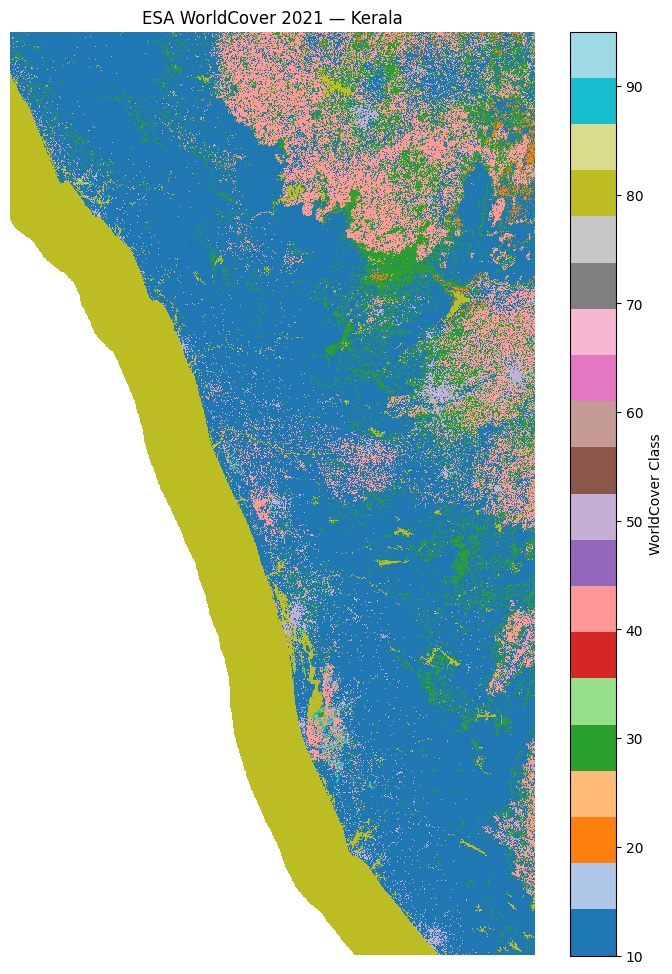

In [53]:
# Memory-safe visualization of Kerala WorldCover

import rasterio
import matplotlib.pyplot as plt

with rasterio.open(LANDCOVER) as src:

    # Read a reduced-resolution preview instead of full raster
    preview_height = src.height // 10
    preview_width = src.width // 10

    landcover_preview = src.read(
        1,
        out_shape=(
            preview_height,
            preview_width
        ),
        masked=True
    )

print("Preview shape:", landcover_preview.shape)

plt.figure(figsize=(9, 12))

plt.imshow(
    landcover_preview,
    cmap="tab20",
    interpolation="nearest"
)

plt.title("ESA WorldCover 2021 — Kerala")
plt.colorbar(label="WorldCover Class")

plt.axis("off")
plt.show()

### Optional NDVI note

NDVI can be a strong continuous vegetation-density indicator, but a **single Sentinel-2 scene is not sufficient for statewide Kerala**. A defensible statewide NDVI factor should be built from multiple cloud-masked scenes using a consistent season/date window and mosaicked before this notebook samples it.

If you later create a statewide NDVI GeoTIFF, set:

```python
NDVI_RAW_PATH = RAW_DIR / "kerala_ndvi.tif"
```

in the configuration cell and rerun the static-factor preparation/sampling cells.


In [55]:
# 13 — Save ESA WorldCover class legend for reproducibility

WORLDCOVER_LEGEND = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare / sparse vegetation",
    70: "Snow and ice",
    80: "Permanent water bodies",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss and lichen",
}

legend_df = pd.DataFrame(
    [{"landcover": k, "class_name": v} for k, v in WORLDCOVER_LEGEND.items()]
)
legend_path = PROCESSED_DIR / "worldcover_2021_class_legend.csv"
legend_df.to_csv(legend_path, index=False)

print("Saved WorldCover legend:", legend_path)
legend_df


Saved WorldCover legend: D:\PROJECTS\Landslide_prediction\data\processed\worldcover_2021_class_legend.csv


,landcover,class_name
0,10,Tree cover
1,20,Shrubland
2,30,Grassland
3,40,Cropland
4,50,Built-up
5,60,Bare / sparse vegetation
6,70,Snow and ice
7,80,Permanent water bodies
8,90,Herbaceous wetland
9,95,Mangroves


## 7. Distance-to-river / distance-to-road

`distriv` and `distroad` are **excluded from this Kerala version**. Multiple live Overpass approaches were tested but were not reliable enough for a reproducible state-scale research pipeline. This limitation is recorded in the manifest.

They should only be added later from a stable local vector source (for example, a locally downloaded OSM extract or an authoritative Kerala hydrography/road dataset).


In [56]:
# 14 — Record skipped OSM factors

DISTRIV_AVAILABLE = False
DISTROAD_AVAILABLE = False

print("distriv/distroad skipped in this reproducible version.")


distriv/distroad skipped in this reproducible version.


## 8. Generate balanced pseudo-absence points

In [61]:
# 15 — Prepare landslide points for modelling

landslides_utm = kerala_wgs84.to_crs(TARGET_CRS).copy()

landslides_utm["lslpts"] = "TRUE"
landslides_utm["label"] = 1
landslides_utm["source"] = "Kerala_Landslide_Inventory"
landslides_utm["X"] = landslides_utm.geometry.x
landslides_utm["Y"] = landslides_utm.geometry.y

state_utm = kerala_boundary.to_crs(TARGET_CRS)
state_geom_utm = state_utm.geometry.union_all()

exclusion_geom = (
    landslides_utm.geometry
    .buffer(EXCLUSION_BUFFER_M)
    .union_all()
)

allowed_geom = state_geom_utm.difference(exclusion_geom)

if allowed_geom.is_empty:
    raise ValueError("Pseudo-absence sampling area is empty.")

print("Landslide samples     :", len(landslides_utm))
print("Pseudo-absence target :", len(landslides_utm))


Landslide samples     : 4728
Pseudo-absence target : 4728


In [58]:
# 16 — Reproducible pseudo-absence sampling

def generate_pseudo_absences(
    n_required,
    allowed_polygon,
    dem_path,
    seed=42,
    batch_size=20000
):
    rng = np.random.default_rng(seed)
    allowed_prepared = prep(allowed_polygon)
    minx, miny, maxx, maxy = allowed_polygon.bounds

    accepted = []
    seen = set()

    with rasterio.open(dem_path) as dem:
        nodata = dem.nodata

        while len(accepted) < n_required:
            xs = rng.uniform(minx, maxx, batch_size)
            ys = rng.uniform(miny, maxy, batch_size)

            candidates = []
            for x, y in zip(xs, ys):
                p = Point(float(x), float(y))

                if allowed_prepared.contains(p):
                    key = (round(x, 3), round(y, 3))
                    if key not in seen:
                        candidates.append(p)
                        seen.add(key)

            if not candidates:
                continue

            vals = np.array(
                [v[0] for v in dem.sample([(p.x, p.y) for p in candidates])],
                dtype="float64"
            )

            valid = np.isfinite(vals)
            if nodata is not None:
                valid &= vals != nodata

            for p, ok in zip(candidates, valid):
                if ok:
                    accepted.append(p)
                    if len(accepted) == n_required:
                        break

            print(f"Accepted {len(accepted):,}/{n_required:,}", end="\r")

    print()
    return gpd.GeoDataFrame({"geometry": accepted}, crs=TARGET_CRS)


NONLANDSLIDE_GPKG = PROCESSED_DIR / "kerala_pseudo_absence_points.gpkg"

if NONLANDSLIDE_GPKG.exists():
    non_landslides_utm = gpd.read_file(NONLANDSLIDE_GPKG)

    if len(non_landslides_utm) != len(landslides_utm):
        raise ValueError(
            "Cached pseudo-absence count does not match the landslide count. "
            "Delete kerala_pseudo_absence_points.gpkg and regenerate."
        )

    print("Loaded cached pseudo-absence points.")

else:
    non_landslides_utm = generate_pseudo_absences(
        len(landslides_utm),
        allowed_geom,
        DEM_UTM,
        seed=RANDOM_STATE
    )

    non_landslides_utm.to_file(
        NONLANDSLIDE_GPKG,
        layer="pseudo_absence",
        driver="GPKG"
    )

    print("Saved pseudo-absence points:", NONLANDSLIDE_GPKG)


non_landslides_utm["lslpts"] = "FALSE"
non_landslides_utm["label"] = 0
non_landslides_utm["source"] = "Kerala_Pseudo_Absence"
non_landslides_utm["X"] = non_landslides_utm.geometry.x
non_landslides_utm["Y"] = non_landslides_utm.geometry.y

print(non_landslides_utm["label"].value_counts())


Accepted 4,728/4,728
Saved pseudo-absence points: D:\PROJECTS\Landslide_prediction\data\processed\kerala_pseudo_absence_points.gpkg
label
0    4728
Name: count, dtype: int64


## 9. Combine landslide and pseudo-absence samples

In [59]:
# 17 — Build balanced modelling points

base_cols = ["lslpts", "X", "Y", "geometry", "label", "source"]

combined = pd.concat(
    [
        landslides_utm[base_cols],
        non_landslides_utm[base_cols]
    ],
    ignore_index=True
)

combined = gpd.GeoDataFrame(
    combined,
    geometry="geometry",
    crs=TARGET_CRS
)

print(combined["label"].value_counts())
print("Total:", len(combined))

if combined["label"].value_counts().nunique() != 1:
    raise ValueError("Classes are not balanced.")


label
1    4728
0    4728
Name: count, dtype: int64
Total: 9456


## 10. Sample every available raster factor at all modelling points

In [ ]:
# ==========================================================
# 18 — Sample all raster factors at modelling points
# ==========================================================

from pathlib import Path
import numpy as np
import rasterio


# ----------------------------------------------------------
# 18.1 Raster sampling helper
# ----------------------------------------------------------

def sample_raster_at_points(raster_path, points_gdf, band=1):
    raster_path = Path(raster_path)
    with rasterio.open(raster_path) as src:

        # Reproject points if needed
        if points_gdf.crs != src.crs:
            pts = points_gdf.to_crs(src.crs)
        else:
            pts = points_gdf

        # Point coordinates
        coords = [
            (geom.x, geom.y)
            for geom in pts.geometry
        ]

        # Sample raster
        values = np.array(
            [
                value[band - 1]
                for value in src.sample(coords)
            ],
            dtype="float64"
        )

        # Replace nodata with NaN
        if src.nodata is not None:
            values[values == src.nodata] = np.nan

        # Replace invalid values with NaN
        values[~np.isfinite(values)] = np.nan

    return values


# ----------------------------------------------------------
# 18.2 Terrain factors
# ----------------------------------------------------------

terrain_rasters = {
    "elev": DEM_UTM,
    "aspect": ASPECT,
    "planc": PLANC,
    "profc": PROFC,
    "slope": SLOPE,
    "spi": SPI,
    "twi": TWI,
}

continuous_factor_columns = []

print("Terrain factors")
print("----------------")

for name, path in terrain_rasters.items():

    combined[name] = sample_raster_at_points(
        path,
        combined
    )

    continuous_factor_columns.append(name)

    print(
        f"{name:10s}: "
        f"{combined[name].notna().sum():,}/{len(combined):,} valid"
    )


# ----------------------------------------------------------
# 18.3 SoilGrids factors
# ----------------------------------------------------------

soil_factor_rasters = {

    "clay": {
        "path": CLAY,
        "divisor": 10.0,
        "unit": "%"
    },

    "sand": {
        "path": SAND,
        "divisor": 10.0,
        "unit": "%"
    },

    "soc": {
        "path": SOC,
        "divisor": 10.0,
        "unit": "g/kg"
    },

    "bdod": {
        "path": BDOD,
        "divisor": 100.0,
        "unit": "kg/dm³"
    },
}


print("\nSoil factors")
print("------------")

for name, info in soil_factor_rasters.items():

    # Sample raw SoilGrids values
    values = sample_raster_at_points(
        info["path"],
        combined
    )

    # Convert SoilGrids stored units
    combined[name] = (
        values / info["divisor"]
    )

    continuous_factor_columns.append(name)

    print(
        f"{name:10s}: "
        f"{combined[name].notna().sum():,}/{len(combined):,} valid "
        f"({info['unit']})"
    )


# ----------------------------------------------------------
# 18.4 ESA WorldCover
# ----------------------------------------------------------

categorical_factor_columns = []

print("\nLand-cover factors")
print("------------------")

if (
    LANDCOVER is not None
    and Path(LANDCOVER).exists()
):

    combined["landcover"] = sample_raster_at_points(
        LANDCOVER,
        combined
    )

    # WorldCover nodata = 0
    combined.loc[
        combined["landcover"] == 0,
        "landcover"
    ] = np.nan

    categorical_factor_columns.append(
        "landcover"
    )

    print(
        f"{'landcover':10s}: "
        f"{combined['landcover'].notna().sum():,}/{len(combined):,} valid"
    )

else:

    print("WorldCover raster not available.")


# ----------------------------------------------------------
# 18.5 Optional NDVI
# ----------------------------------------------------------

# NDVI is currently optional.
# This section only runs if an NDVI variable exists
# and points to an existing raster.

if "NDVI" in globals():

    if (
        NDVI is not None
        and Path(NDVI).exists()
    ):

        combined["ndvi"] = sample_raster_at_points(
            NDVI,
            combined
        )

        continuous_factor_columns.append(
            "ndvi"
        )

        print(
            f"{'ndvi':10s}: "
            f"{combined['ndvi'].notna().sum():,}/{len(combined):,} valid"
        )


# ----------------------------------------------------------
# 18.6 Final factor lists
# ----------------------------------------------------------

model_factor_columns = (
    continuous_factor_columns
    + categorical_factor_columns
)


print("\n====================================")
print("FINAL FACTOR LIST")
print("====================================")

print(
    "\nContinuous factors:"
)

for factor in continuous_factor_columns:
    print(" -", factor)


print(
    "\nCategorical factors:"
)

for factor in categorical_factor_columns:
    print(" -", factor)


print(
    "\nTotal model factors:",
    len(model_factor_columns)
)


# ----------------------------------------------------------
# 18.7 Missing-value summary
# ----------------------------------------------------------

print("\n====================================")
print("VALID / MISSING VALUES")
print("====================================")

for factor in model_factor_columns:

    valid = combined[factor].notna().sum()
    missing = combined[factor].isna().sum()

    print(
        f"{factor:10s}: "
        f"{valid:,} valid | "
        f"{missing:,} missing"
    )


# ----------------------------------------------------------
# 18.8 Quick numerical check
# ----------------------------------------------------------

print("\n====================================")
print("CONTINUOUS FACTOR STATISTICS")
print("====================================")

display(
    combined[
        continuous_factor_columns
    ].describe().T
)


# ----------------------------------------------------------
# 18.9 Check WorldCover classes
# ----------------------------------------------------------

if "landcover" in combined.columns:

    print("\n====================================")
    print("WORLDCOVER CLASSES")
    print("====================================")

    worldcover_classes = {
        10: "Tree cover",
        20: "Shrubland",
        30: "Grassland",
        40: "Cropland",
        50: "Built-up",
        60: "Bare / sparse vegetation",
        70: "Snow and ice",
        80: "Permanent water",
        90: "Herbaceous wetland",
        95: "Mangroves",
        100: "Moss and lichen",
    }

    class_counts = (
        combined["landcover"]
        .dropna()
        .astype(int)
        .value_counts()
        .sort_index()
    )

    for code, count in class_counts.items():

        class_name = worldcover_classes.get(
            code,
            "Unknown"
        )

        print(
            f"{code:3d} | "
            f"{class_name:25s} | "
            f"{count:,}"
        )


print("\n✅ Raster-factor sampling completed.")

Terrain factors
----------------
elev      : 9,446/9,456 valid
aspect    : 9,446/9,456 valid
planc     : 9,446/9,456 valid
profc     : 9,446/9,456 valid
slope     : 9,446/9,456 valid
spi       : 9,446/9,456 valid
twi       : 9,446/9,456 valid

Soil factors
------------
clay      : 9,456/9,456 valid (%)
sand      : 9,456/9,456 valid (%)
soc       : 9,456/9,456 valid (g/kg)
bdod      : 9,456/9,456 valid (kg/dm³)

Land-cover factors
------------------
landcover : 9,456/9,456 valid

FINAL FACTOR LIST

Continuous factors:
 - elev
 - aspect
 - planc
 - profc
 - slope
 - spi
 - twi
 - clay
 - sand
 - soc
 - bdod

Categorical factors:
 - landcover

Total model factors: 12

VALID / MISSING VALUES
elev      : 9,446 valid | 10 missing
aspect    : 9,446 valid | 10 missing
planc     : 9,446 valid | 10 missing
profc     : 9,446 valid | 10 missing
slope     : 9,446 valid | 10 missing
spi       : 9,446 valid | 10 missing
twi       : 9,446 valid | 10 missing
clay      : 9,456 valid | 0 missing
sand    

,count,mean,std,min,25%,50%,75%,max
elev,9446.0,530.363120,486.471196,-8.280469,70.864349,464.885666,847.134476,2.486739e+03
aspect,9446.0,173.545865,101.233263,-1.000000,85.780388,179.998558,248.488895,3.598652e+02
planc,9446.0,-0.001446,0.037097,-2.031784,-0.003753,0.000443,0.004656,5.819736e-01
profc,9446.0,-0.000032,0.001862,-0.017780,-0.000969,-0.000082,0.000796,1.736508e-02
slope,9446.0,17.458870,12.733625,0.000403,5.346924,17.018548,27.470008,7.425866e+01
spi,9446.0,644.436088,21719.443453,0.000211,8.103532,28.724451,73.301037,1.890361e+06
twi,9446.0,6.630879,2.620156,2.598801,5.107853,5.953766,7.117725,2.901762e+01
clay,9456.0,30.502459,6.005516,0.000000,29.832558,31.683797,33.210759,4.099669e+01
sand,9456.0,38.347863,8.310196,0.000000,36.223334,38.965309,42.746114,6.386329e+01
soc,9456.0,45.676040,14.389294,0.000000,38.037928,44.570837,53.679619,1.300727e+02



WORLDCOVER CLASSES
 10 | Tree cover                | 8,256
 30 | Grassland                 | 697
 40 | Cropland                  | 177
 50 | Built-up                  | 152
 60 | Bare / sparse vegetation  | 4
 80 | Permanent water           | 131
 90 | Herbaceous wetland        | 38
 95 | Mangroves                 | 1

✅ Raster-factor sampling completed.


## 11. Optional geology

Geology is retained as an optional extension. If a Kerala-wide geology raster/vector becomes available, set `GEOLOGY_PATH` and (for vector data) `GEOLOGY_FIELD` in the configuration cell.


In [65]:
# ==========================================================
# Geology — Download GLiM lithology polygons for Kerala
# ==========================================================

import requests
import geopandas as gpd
import pandas as pd
from pathlib import Path


GEOLOGY_DIR = RAW_DIR / "geology"
GEOLOGY_DIR.mkdir(parents=True, exist_ok=True)

GEOLOGY_RAW_PATH = GEOLOGY_DIR / "kerala_glim_geology.gpkg"

GLIM_URL = (
    "https://services8.arcgis.com/"
    "4KhTMTZ1x0f76DSg/ArcGIS/rest/services/"
    "GLiM_Niveau_I/FeatureServer/1/query"
)


if GEOLOGY_RAW_PATH.exists():

    print("Loading saved Kerala geology...")

    geology_kerala = gpd.read_file(
        GEOLOGY_RAW_PATH
    )

else:

    print("Downloading GLiM geology for Kerala...")

    # Kerala bounding box
    boundary_wgs84 = kerala_boundary.to_crs("EPSG:4326")

    minx, miny, maxx, maxy = (
        boundary_wgs84.total_bounds
    )

    geometry_string = (
        f"{minx},{miny},{maxx},{maxy}"
    )

    all_features = []

    offset = 0
    batch_size = 1000

    while True:

        params = {
            "where": "1=1",

            "geometry": geometry_string,
            "geometryType": "esriGeometryEnvelope",

            "inSR": "4326",
            "outSR": "4326",

            "spatialRel":
                "esriSpatialRelIntersects",

            "outFields":
                "OBJECTID,Litho,xx_Description",

            "returnGeometry": "true",

            "resultOffset": offset,
            "resultRecordCount": batch_size,

            "f": "geojson"
        }

        response = requests.get(
            GLIM_URL,
            params=params,
            timeout=120
        )

        response.raise_for_status()

        data = response.json()

        features = data.get(
            "features",
            []
        )

        if len(features) == 0:
            break

        all_features.extend(features)

        print(
            f"Downloaded {len(all_features)} polygons..."
        )

        if len(features) < batch_size:
            break

        offset += batch_size


    if len(all_features) == 0:

        raise RuntimeError(
            "No geology features were returned."
        )


    geology_kerala = gpd.GeoDataFrame.from_features(
        all_features,
        crs="EPSG:4326"
    )


    # Keep useful columns only
    geology_kerala = geology_kerala[
        [
            "OBJECTID",
            "Litho",
            "xx_Description",
            "geometry"
        ]
    ].copy()


    # Clip exactly to Kerala
    geology_kerala = gpd.clip(
        geology_kerala,
        boundary_wgs84
    )


    geology_kerala = (
        geology_kerala
        .reset_index(drop=True)
    )


    geology_kerala.to_file(
        GEOLOGY_RAW_PATH,
        layer="geology",
        driver="GPKG"
    )

    print(
        "Saved:",
        GEOLOGY_RAW_PATH
    )


print("\nNumber of geology polygons:",
      len(geology_kerala))

print("\nGeology classes:")

print(
    geology_kerala[
        "xx_Description"
    ].value_counts()
)

Downloaded 231 polygons...
Saved: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\geology\kerala_glim_geology.gpkg

Number of geology polygons: 150

Geology classes:
xx_Description
Metamorphics                       81
Acid plutonic rocks                33
Mixed sedimentary rocks            12
Unconsolidated sediments           11
Carbonate sedimentary rocks         5
Basic plutonic rocks                5
Intermediate plutonic rocks         1
Siliciclastic sedimentary rocks     1
Water Bodies                        1
Name: count, dtype: int64


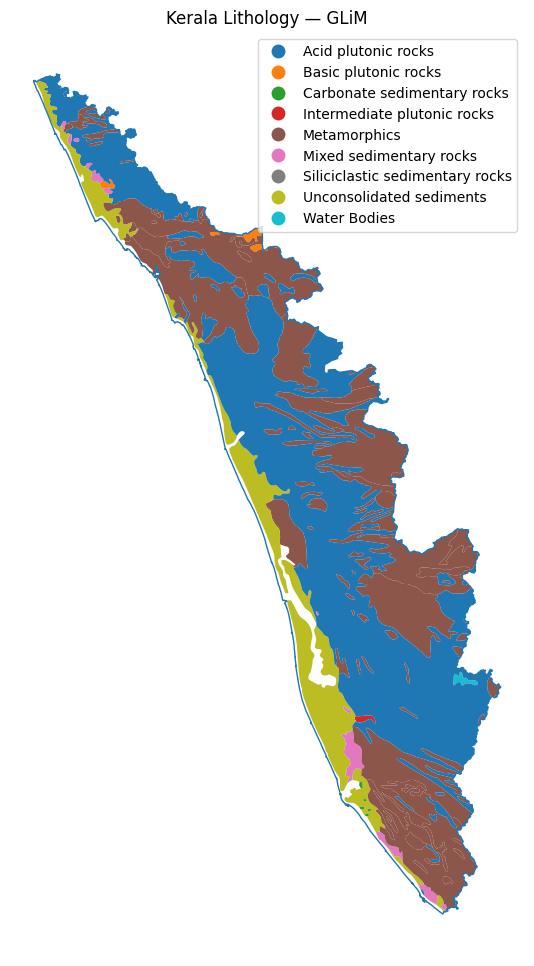

In [66]:
# ==========================================================
# Visualize Kerala geology
# ==========================================================

import matplotlib.pyplot as plt


fig, ax = plt.subplots(
    figsize=(10, 12)
)


geology_kerala.plot(
    column="xx_Description",
    categorical=True,
    legend=True,
    ax=ax
)


kerala_boundary.to_crs(
    geology_kerala.crs
).boundary.plot(
    ax=ax,
    linewidth=1
)


ax.set_title(
    "Kerala Lithology — GLiM"
)

ax.axis("off")

plt.show()

In [ ]:

# Encode geology classes

geology_kerala["geology_name"] = (
    geology_kerala["xx_Description"]
    .astype(str)
    .str.strip()
)

# Remove explicit No Data polygons
geology_kerala = geology_kerala[
    geology_kerala["geology_name"] != "No Data"
].copy()

geology_classes = sorted(
    geology_kerala[
        "geology_name"
    ].dropna().unique()
)

geology_mapping = {
    name: code
    for code, name in enumerate(
        geology_classes,
        start=1
    )
}

geology_kerala["geologi"] = (
    geology_kerala[
        "geology_name"
    ].map(
        geology_mapping
    )
)


print("Geology class mapping:")

for name, code in geology_mapping.items():

    print(
        f"{code:2d} = {name}"
    )

Geology class mapping:
 1 = Acid plutonic rocks
 2 = Basic plutonic rocks
 3 = Carbonate sedimentary rocks
 4 = Intermediate plutonic rocks
 5 = Metamorphics
 6 = Mixed sedimentary rocks
 7 = Siliciclastic sedimentary rocks
 8 = Unconsolidated sediments
 9 = Water Bodies


In [68]:
geology_legend = pd.DataFrame(
    {
        "geologi": list(
            geology_mapping.values()
        ),

        "geology_name": list(
            geology_mapping.keys()
        )
    }
)


GEOLOGY_LEGEND_PATH = (
    PROCESSED_DIR /
    "kerala_geology_legend.csv"
)


geology_legend.to_csv(
    GEOLOGY_LEGEND_PATH,
    index=False
)


print(
    "Saved:",
    GEOLOGY_LEGEND_PATH
)

Saved: D:\PROJECTS\Landslide_prediction\data\processed\kerala_geology_legend.csv


In [69]:
# ==========================================================
# Add geology to combined modelling points
# ==========================================================

geology_for_join = (
    geology_kerala[
        [
            "geologi",
            "geology_name",
            "geometry"
        ]
    ]
    .to_crs(
        combined.crs
    )
)


combined_with_id = (
    combined
    .reset_index()
    .rename(
        columns={
            "index": "point_id"
        }
    )
)


geology_join = gpd.sjoin(
    combined_with_id,
    geology_for_join,
    how="left",
    predicate="within"
)


# Handle possible boundary overlaps by
# keeping one geology result per point
geology_join = (
    geology_join
    .sort_values("point_id")
    .drop_duplicates(
        subset="point_id"
    )
)


geology_values = (
    geology_join
    .set_index("point_id")[
        "geologi"
    ]
)


geology_names = (
    geology_join
    .set_index("point_id")[
        "geology_name"
    ]
)


combined["geologi"] = (
    combined.index.to_series()
    .map(geology_values)
)


combined["geology_name"] = (
    combined.index.to_series()
    .map(geology_names)
)


print(
    "Valid geology:",
    combined["geologi"].notna().sum(),
    "/",
    len(combined)
)


print("\nGeology distribution:")

print(
    combined[
        "geology_name"
    ].value_counts(
        dropna=False
    )
)

Valid geology: 9264 / 9456

Geology distribution:
geology_name
Metamorphics                   4790
Acid plutonic rocks            3877
Unconsolidated sediments        506
NaN                             192
Mixed sedimentary rocks          59
Basic plutonic rocks             19
Intermediate plutonic rocks       6
Water Bodies                      5
Carbonate sedimentary rocks       2
Name: count, dtype: int64


In [71]:
if "geologi" in combined.columns:
    categorical_factor_columns.append(
        "geologi"
    )

## 12. Quality control and save the Kerala dataset

In [74]:
# Final factor lists

categorical_factor_columns = []

if "landcover" in combined.columns:
    categorical_factor_columns.append("landcover")

if "geologi" in combined.columns:
    categorical_factor_columns.append("geologi")

model_factor_columns = (
    continuous_factor_columns
    + categorical_factor_columns
)

print("Continuous factors :", continuous_factor_columns)
print("Categorical factors:", categorical_factor_columns)
print("All model factors  :", model_factor_columns)

Continuous factors : ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod']
Categorical factors: ['landcover', 'geologi']
All model factors  : ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod', 'landcover', 'geologi']


In [75]:
# 20 — Quality-control report

report_columns = [
    "lslpts", "X", "Y", "geometry", "label", "source"
] + model_factor_columns

print("Rows:", len(combined))

print("\nClass balance:")
print(combined["label"].value_counts())

print("\nMissing values (%):")
print(
    (combined[report_columns].isna().mean() * 100)
    .round(2)
)

print(
    "\nDuplicate modelling geometries:",
    combined.geometry.duplicated().sum()
)

factor_missing = combined[model_factor_columns].isna().sum()

if factor_missing.any():
    print("\nWARNING — missing factor values:")
    print(factor_missing[factor_missing > 0])
else:
    print("\nAll selected factor values are complete.")

print("\nFinal continuous factors :", continuous_factor_columns)
print("Final categorical factors:", categorical_factor_columns)


Rows: 9456

Class balance:
label
1    4728
0    4728
Name: count, dtype: int64

Missing values (%):
lslpts       0.00
X            0.00
Y            0.00
geometry     0.00
label        0.00
source       0.00
elev         0.11
aspect       0.11
planc        0.11
profc        0.11
slope        0.11
spi          0.11
twi          0.11
clay         0.00
sand         0.00
soc          0.00
bdod         0.00
landcover    0.00
geologi      2.03
dtype: float64

Duplicate modelling geometries: 0

WARNING — missing factor values:
elev        10
aspect      10
planc       10
profc       10
slope       10
spi         10
twi         10
geologi    192
dtype: int64

Final continuous factors : ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod']
Final categorical factors: ['landcover', 'geologi']


In [76]:
# 21 — Save the extended Kerala susceptibility dataset

BASE_COLUMNS = [
    "lslpts", "X", "Y", "geometry", "label", "source"
]

FINAL_COLUMNS = BASE_COLUMNS + model_factor_columns

def save_geocsv(gdf, path, columns):
    out = gdf[columns].copy()
    out["geometry"] = out.geometry.to_wkt()
    out.to_csv(path, index=False, encoding="utf-8-sig")
    return path

FINAL_CSV = PROCESSED_DIR / "training_table_kerala_extended.csv"
FINAL_PARQUET = PROCESSED_DIR / "training_table_kerala_extended.parquet"

save_geocsv(combined, FINAL_CSV, FINAL_COLUMNS)
combined[FINAL_COLUMNS].to_parquet(FINAL_PARQUET, index=False)

print("Saved CSV    :", FINAL_CSV)
print("Saved Parquet:", FINAL_PARQUET)
print("Shape        :", combined[FINAL_COLUMNS].shape)
print("Factors      :", model_factor_columns)


Saved CSV    : D:\PROJECTS\Landslide_prediction\data\processed\training_table_kerala_extended.csv
Saved Parquet: D:\PROJECTS\Landslide_prediction\data\processed\training_table_kerala_extended.parquet
Shape        : (9456, 19)
Factors      : ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod', 'landcover', 'geologi']


In [78]:
# ==========================================================
# 22 — Reproducibility manifest
# ==========================================================

from datetime import datetime, timezone
import json


# ----------------------------------------------------------
# Factor source files
# ----------------------------------------------------------

factor_sources = {

    # Terrain
    "elev": str(DEM_UTM),
    "aspect": str(ASPECT),
    "planc": str(PLANC),
    "profc": str(PROFC),
    "slope": str(SLOPE),
    "spi": str(SPI),
    "twi": str(TWI),

    # SoilGrids
    "clay": str(CLAY),
    "sand": str(SAND),
    "soc": str(SOC),
    "bdod": str(BDOD),
}


# ----------------------------------------------------------
# ESA WorldCover
# ----------------------------------------------------------

if (
    "LANDCOVER" in globals()
    and LANDCOVER is not None
    and Path(LANDCOVER).exists()
):
    factor_sources["landcover"] = str(LANDCOVER)


# ----------------------------------------------------------
# Geology
# ----------------------------------------------------------

if (
    "GEOLOGY_RAW_PATH" in globals()
    and GEOLOGY_RAW_PATH is not None
    and Path(GEOLOGY_RAW_PATH).exists()
):
    factor_sources["geologi"] = str(GEOLOGY_RAW_PATH)


# ----------------------------------------------------------
# Optional NDVI
# ----------------------------------------------------------

if (
    "NDVI" in globals()
    and NDVI is not None
    and Path(NDVI).exists()
):
    factor_sources["ndvi"] = str(NDVI)


# ----------------------------------------------------------
# Manifest
# ----------------------------------------------------------

manifest = {

    "created_utc":
        datetime.now(timezone.utc).isoformat(),

    # Source data
    "source_data_dir":
        str(RAW_DIR),

    "source_inventory":
        str(INVENTORY_PATH),

    "source_landslide_count":
        int(len(kerala_raw)),

    "pseudo_absence_count":
        int((combined["label"] == 0).sum()),

    "total_samples":
        int(len(combined)),

    # Spatial configuration
    "target_crs":
        TARGET_CRS,

    "target_resolution_m":
        TARGET_RESOLUTION_M,

    "random_state":
        RANDOM_STATE,

    "exclusion_buffer_m":
        EXCLUSION_BUFFER_M,

    # Factors
    "continuous_factors":
        continuous_factor_columns,

    "categorical_factors":
        categorical_factor_columns,

    "total_model_factors":
        len(model_factor_columns),

    "factor_sources":
        factor_sources,

    # SoilGrids metadata
    "soilgrids_product":
        "SoilGrids 2.0",

    "soilgrids_depth":
        "0-5 cm mean",

    "soilgrids_native_resolution_m":
        250,

    "soilgrids_variables": {
        "clay": "Clay content (%)",
        "sand": "Sand content (%)",
        "soc": "Soil organic carbon (g/kg)",
        "bdod": "Bulk density (kg/dm3)"
    },

    # WorldCover metadata
    "worldcover_product":
        "ESA WorldCover 2021 v200",

    "worldcover_native_resolution_m":
        10,

    "worldcover_factor":
        "landcover",

    # Geology metadata
    "geology_product":
        "Global Lithological Map (GLiM)",

    "geology_factor":
        "geologi",

    "geology_type":
        "categorical lithology",

    # Excluded factors
    "factors_excluded": [
        "distriv",
        "distroad"
    ],

    "exclusion_reason": (
        "Distance-to-river and distance-to-road were excluded because "
        "repeated live OSM/Overpass bulk extraction was not reliable "
        "enough for a reproducible state-scale workflow. "
        "No substitute values were fabricated."
    ),
}


# ----------------------------------------------------------
# Save manifest
# ----------------------------------------------------------

MANIFEST_PATH = (
    PROCESSED_DIR /
    "kerala_dataset_manifest.json"
)

MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2
    ),
    encoding="utf-8"
)


print(
    json.dumps(
        manifest,
        indent=2
    )
)

print(
    "\nManifest saved:",
    MANIFEST_PATH
)

{
  "created_utc": "2026-09-03T17:55:22.425193+00:00",
  "source_data_dir": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\Kerala_dataset",
  "source_inventory": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\Kerala_dataset\\Kerela landslide.shp",
  "source_landslide_count": 4728,
  "pseudo_absence_count": 4728,
  "total_samples": 9456,
  "target_crs": "EPSG:32643",
  "target_resolution_m": 30,
  "random_state": 42,
  "exclusion_buffer_m": 1000,
  "continuous_factors": [
    "elev",
    "aspect",
    "planc",
    "profc",
    "slope",
    "spi",
    "twi",
    "clay",
    "sand",
    "soc",
    "bdod"
  ],
  "categorical_factors": [
    "landcover",
    "geologi"
  ],
  "total_model_factors": 13,
  "factor_sources": {
    "elev": "D:\\PROJECTS\\Landslide_prediction\\data\\processed\\kerala_factors\\map_elev.tif",
    "aspect": "D:\\PROJECTS\\Landslide_prediction\\data\\processed\\kerala_factors\\map_aspect.tif",
    "planc": "D:\\PROJECTS\\Landslide_prediction\\data\\processed\\keral

## 13. Exploratory data analysis (EDA)

In [79]:
# 23 — Load saved dataset for EDA

import matplotlib.pyplot as plt
import seaborn as sns

eda_df = pd.read_csv(FINAL_CSV)

print("Shape:", eda_df.shape)
print("\nClass balance:")
print(eda_df["label"].value_counts())

print("\nMissing factors (%):")
print(
    (eda_df[model_factor_columns].isna().mean() * 100)
    .round(2)
)

eda_df.head()


Shape: (9456, 19)

Class balance:
label
1    4728
0    4728
Name: count, dtype: int64

Missing factors (%):
elev         0.11
aspect       0.11
planc        0.11
profc        0.11
slope        0.11
spi          0.11
twi          0.11
clay         0.00
sand         0.00
soc          0.00
bdod         0.00
landcover    0.00
geologi      2.03
dtype: float64


,lslpts,X,Y,geometry,label,source,elev,aspect,planc,profc,slope,spi,twi,clay,sand,soc,bdod,landcover,geologi
0,True,662615.478996,1.137410e+06,POINT Z (662615.478996 1137410.381485 0),1,Kerala_Landslide_Inventory,124.344223,359.422089,0.003120,-0.000988,26.681540,45.228958,5.187882,30.551273,41.029462,48.239694,1.089525,10.0,1.0
1,True,697166.633037,1.114246e+06,POINT Z (697166.633037 1114246.232484 0),1,Kerala_Landslide_Inventory,593.344238,270.133972,0.007389,0.000379,46.651237,63.561985,4.036674,32.513754,37.684174,54.881525,1.072511,10.0,5.0
2,True,702276.808817,1.116314e+06,POINT Z (702276.808817 1116313.770104 0),1,Kerala_Landslide_Inventory,622.432190,4.774662,-0.002064,0.000357,34.760487,104.099373,5.375925,32.603952,38.984052,45.993784,1.073951,10.0,5.0
3,True,702439.563368,1.135957e+06,POINT Z (702439.563368 1135957.176434 0),1,Kerala_Landslide_Inventory,532.764771,151.006821,0.004381,0.006073,30.131010,17.412092,3.945230,32.394833,36.611581,48.930200,1.089015,10.0,5.0
4,True,707561.365868,1.133953e+06,POINT Z (707561.365868 1133952.827549 0),1,Kerala_Landslide_Inventory,979.343689,251.334686,0.000315,0.001769,53.381409,121.102989,4.202978,33.850275,34.019839,59.070801,1.018513,10.0,5.0


In [ ]:
# 24 — Descriptive statistics for continuous factors by class

if continuous_factor_columns:
    
    display(
        eda_df
        .groupby("label")[continuous_factor_columns]
        .describe()
        .T
    )


label                 0            1
elev count  4728.000000  4718.000000
     mean    266.127363   795.158936
     std     403.940477   412.591148
     min      -8.280469    20.263014
     25%      28.345067   510.763931
...                 ...          ...
bdod min       0.000000     0.000000
     25%       1.096133     1.037261
     50%       1.158883     1.072737
     75%       1.203641     1.108147
     max       1.410000     1.276373

[88 rows x 2 columns]

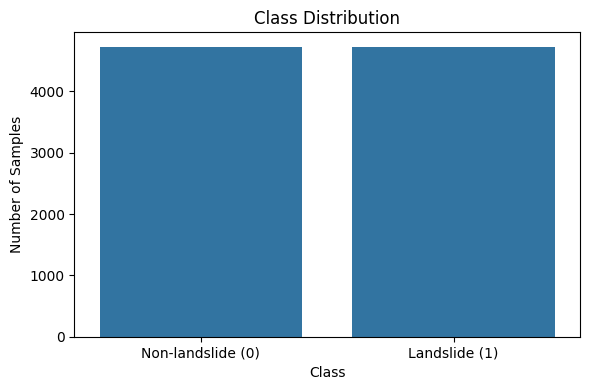

In [93]:
# Class balance visualization

plt.figure(figsize=(6, 4))

sns.countplot(
    data=eda_df,
    x="label"
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.xticks(
    [0, 1],
    [
        "Non-landslide (0)",
        "Landslide (1)"
    ]
)

plt.tight_layout()
plt.show()

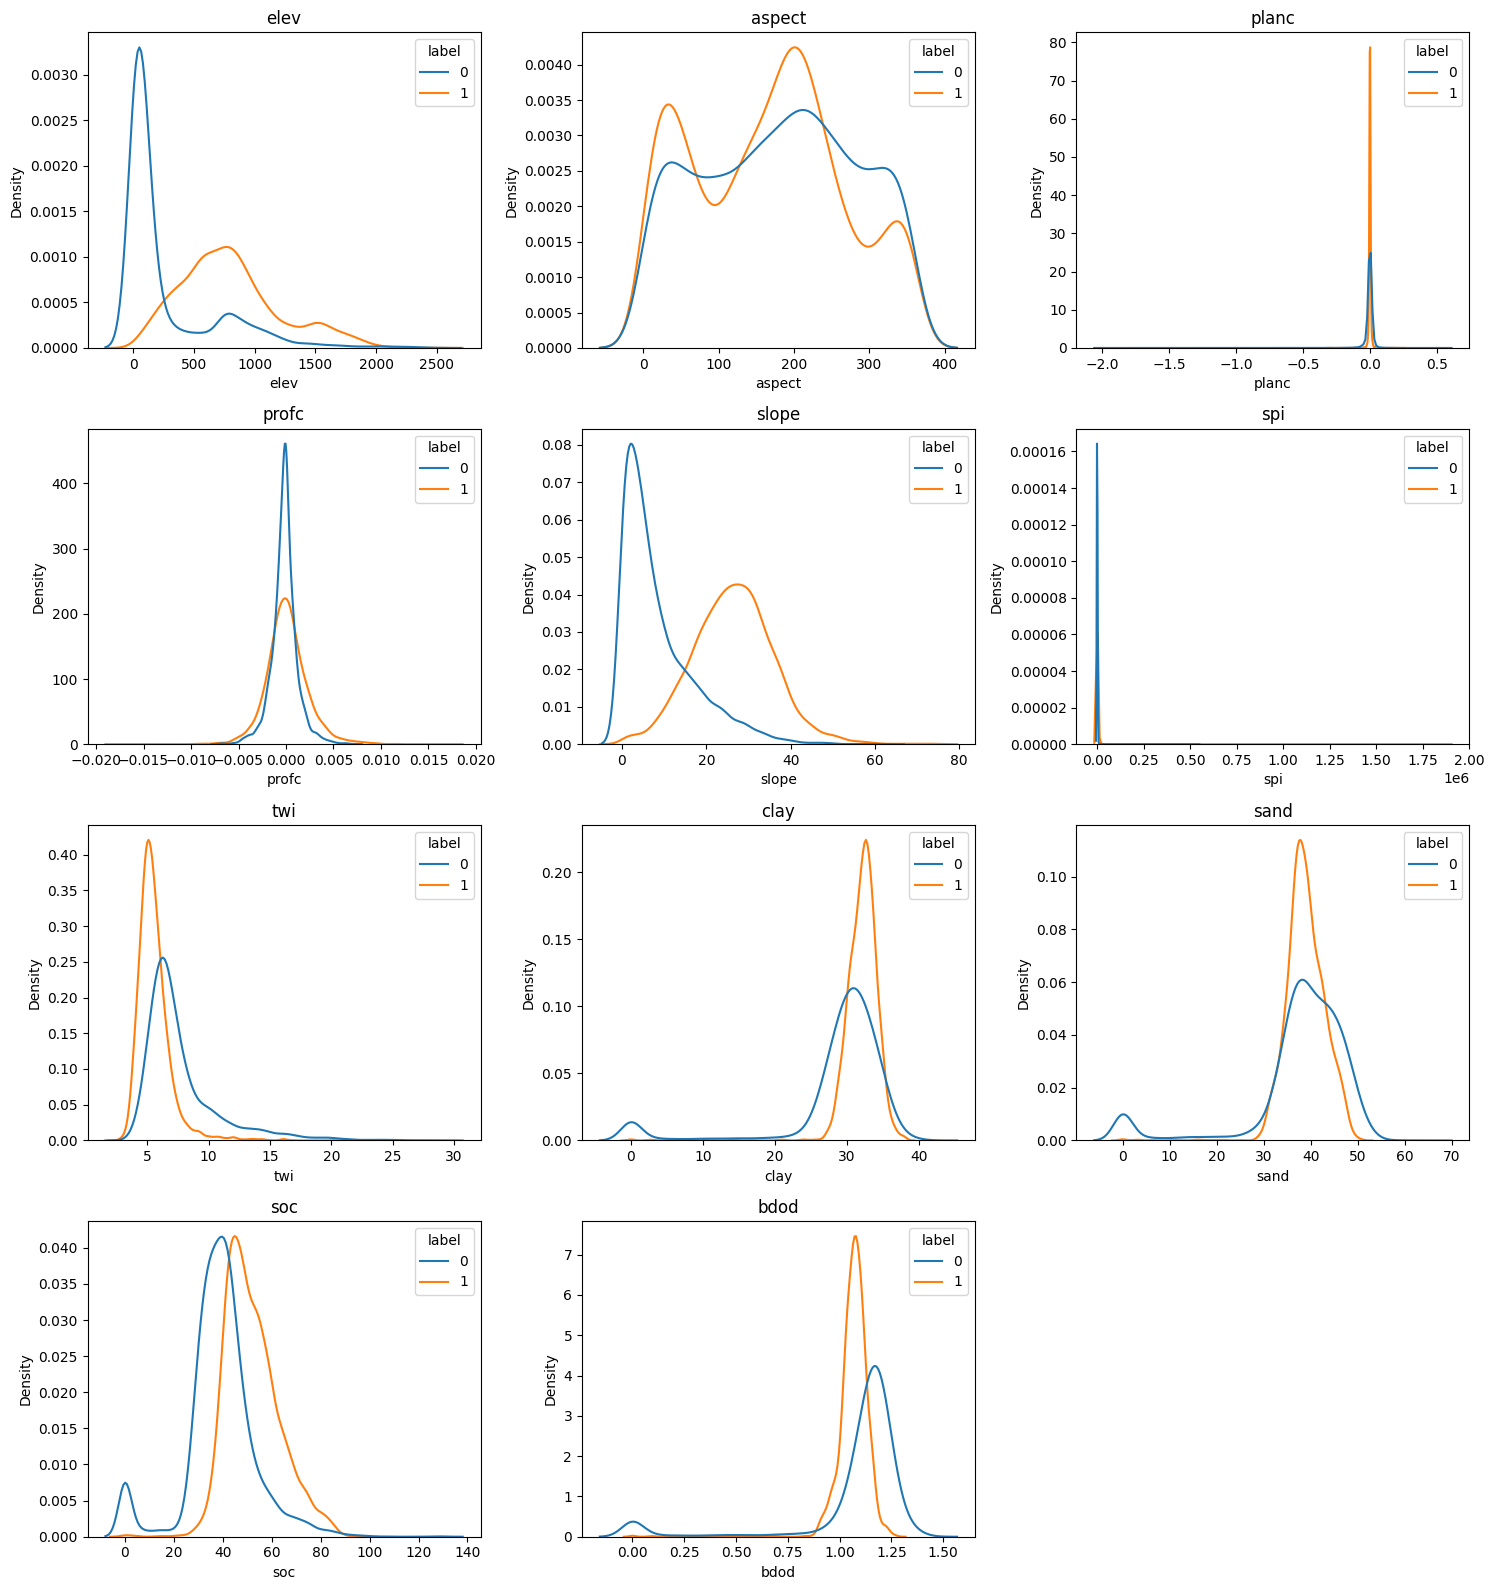

In [81]:
# 25 — Continuous-factor distributions by class

if continuous_factor_columns:
    n = len(continuous_factor_columns)
    ncols = 3
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 4 * nrows)
    )

    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(continuous_factor_columns):
        sns.kdeplot(
            data=eda_df,
            x=col,
            hue="label",
            common_norm=False,
            ax=axes[i]
        )
        axes[i].set_title(col)

    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


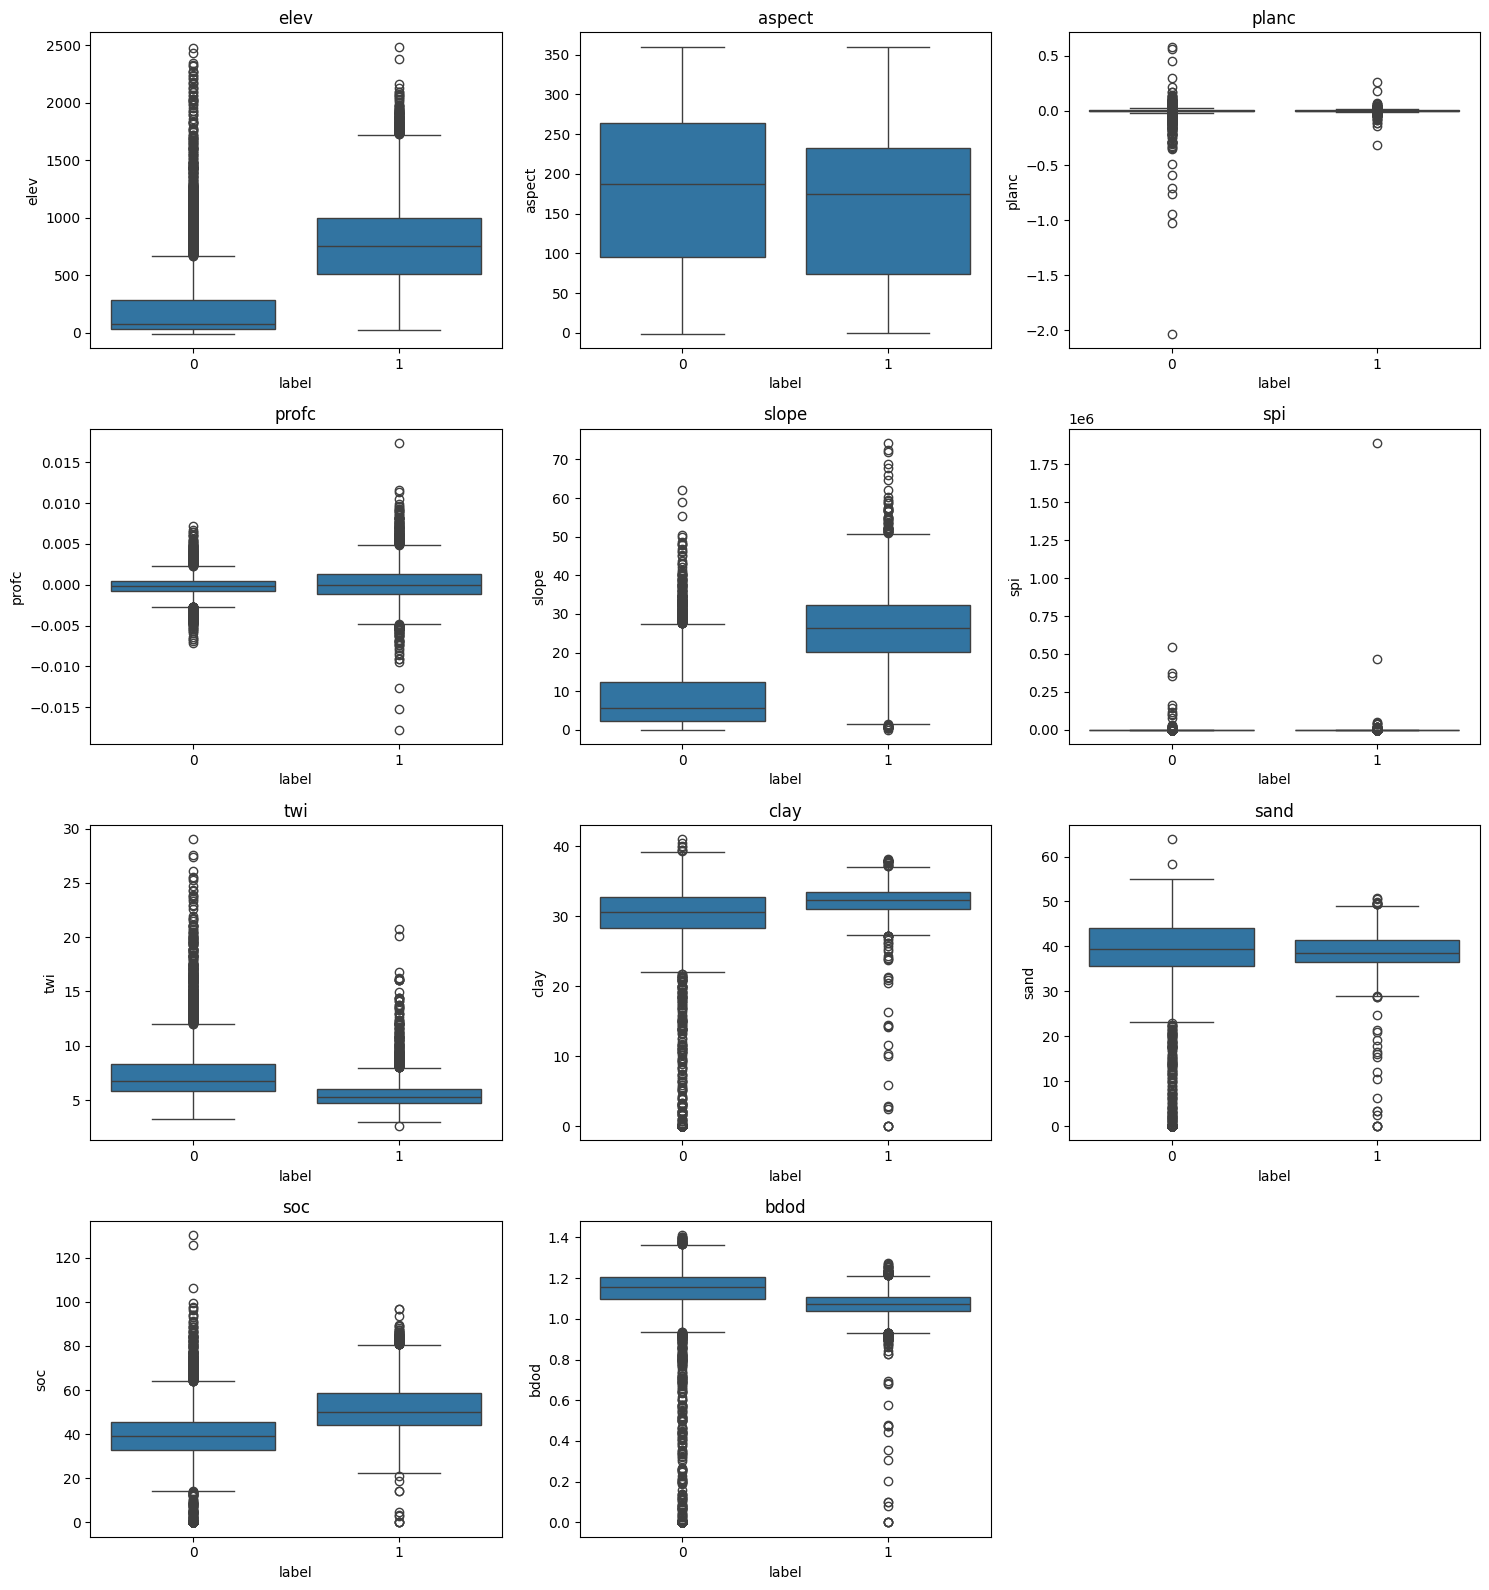

In [82]:
# 26 — Continuous-factor boxplots by class

if continuous_factor_columns:
    n = len(continuous_factor_columns)
    ncols = 3
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 4 * nrows)
    )

    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(continuous_factor_columns):
        sns.boxplot(
            data=eda_df,
            x="label",
            y=col,
            ax=axes[i]
        )
        axes[i].set_title(col)

    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


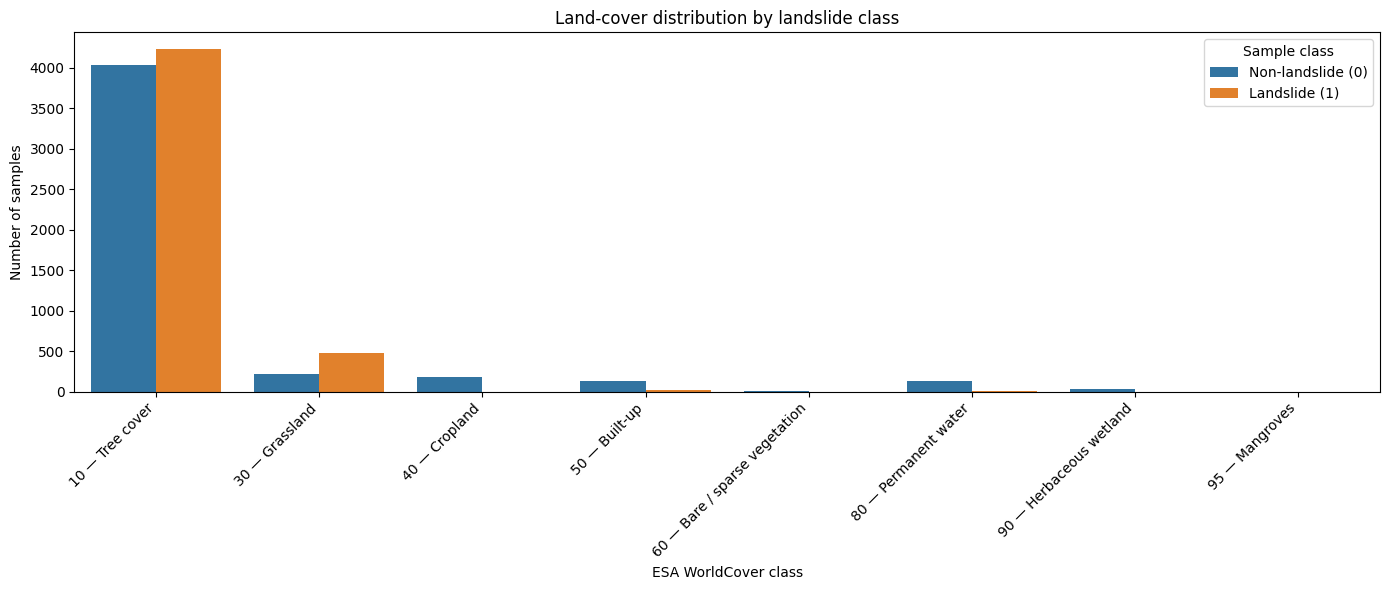

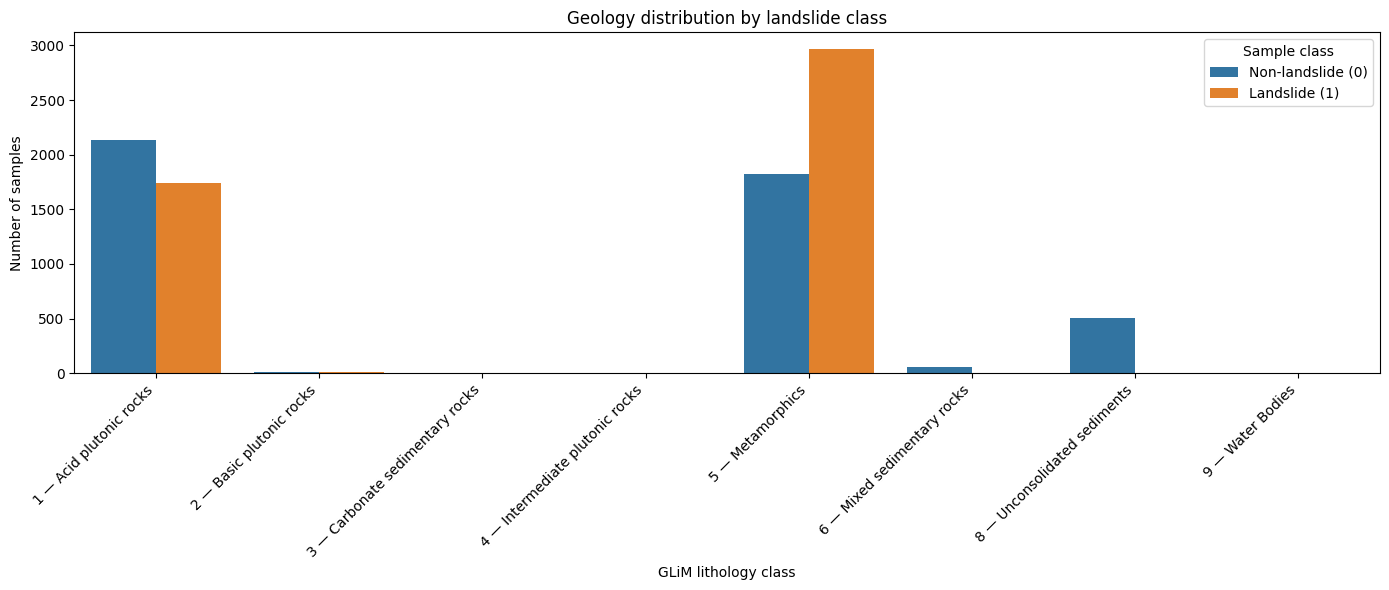

In [87]:
# ==========================================================
# 27 — Categorical factor distributions with class labels
# ==========================================================

# ESA WorldCover class meanings
worldcover_classes = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare / sparse vegetation",
    70: "Snow and ice",
    80: "Permanent water",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss and lichen",
}


# ----------------------------------------------------------
# Build geology code → name mapping
# ----------------------------------------------------------

# Earlier we created:
#
# geology_mapping =
# {
#     "Acid plutonic rocks": 1,
#     "Metamorphics": 2,
#     ...
# }
#
# Reverse it here so:
#
# 1 → "Acid plutonic rocks"

if "geology_mapping" in globals():

    geology_classes = {
        code: name
        for name, code in geology_mapping.items()
    }

elif "geology_legend" in globals():

    geology_classes = dict(
        zip(
            geology_legend["geologi"],
            geology_legend["geology_name"]
        )
    )

else:

    geology_classes = {}


# ----------------------------------------------------------
# Plot categorical factors
# ----------------------------------------------------------

for col in categorical_factor_columns:

    plot_df = eda_df.copy()


    # --------------------------------------
    # Landcover labels
    # --------------------------------------

    if col == "landcover":

        plot_df["category_label"] = (
            plot_df[col]
            .map(worldcover_classes)
        )

        # Include code + description
        plot_df["category_label"] = (
            plot_df[col]
            .astype("Int64")
            .astype(str)
            + " — "
            + plot_df["category_label"]
        )


    # --------------------------------------
    # Geology labels
    # --------------------------------------

    elif col == "geologi":

        plot_df["category_label"] = (
            plot_df[col]
            .map(geology_classes)
        )

        plot_df["category_label"] = (
            plot_df[col]
            .astype("Int64")
            .astype(str)
            + " — "
            + plot_df["category_label"]
        )


    # --------------------------------------
    # Any other categorical variable
    # --------------------------------------

    else:

        plot_df["category_label"] = (
            plot_df[col]
            .astype(str)
        )


    # Remove missing categories
    plot_df = plot_df.dropna(
        subset=["category_label"]
    )


    # Count categories by landslide class
    counts = (
        plot_df
        .groupby(
            ["category_label", "label"]
        )
        .size()
        .reset_index(name="count")
    )


    # --------------------------------------
    # Plot
    # --------------------------------------

    plt.figure(figsize=(14, 6))

    sns.barplot(
        data=counts,
        x="category_label",
        y="count",
        hue="label"
    )


    if col == "landcover":

        plt.title(
            "Land-cover distribution by landslide class"
        )

        plt.xlabel(
            "ESA WorldCover class"
        )


    elif col == "geologi":

        plt.title(
            "Geology distribution by landslide class"
        )

        plt.xlabel(
            "GLiM lithology class"
        )


    else:

        plt.title(
            f"{col} distribution by class"
        )


    plt.ylabel(
        "Number of samples"
    )


    # Explain label = 0 / 1
    handles, labels = (
        plt.gca()
        .get_legend_handles_labels()
    )

    plt.legend(
        handles,
        [
            "Non-landslide (0)",
            "Landslide (1)"
        ],
        title="Sample class"
    )


    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.tight_layout()

    plt.show()

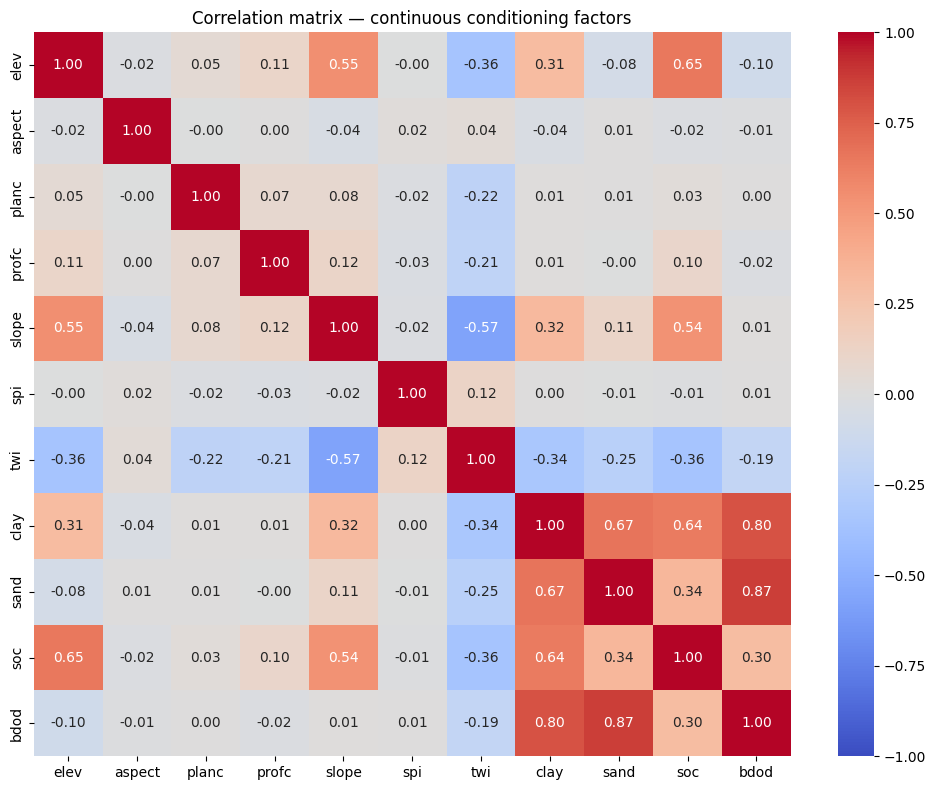

In [84]:
# 28 — Correlation matrix for continuous factors only

if len(continuous_factor_columns) >= 2:
    corr = eda_df[continuous_factor_columns].corr()

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    plt.title("Correlation matrix — continuous conditioning factors")
    plt.tight_layout()
    plt.show()


In [85]:
# 29 — Variance Inflation Factor for continuous factors

from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_df = eda_df[continuous_factor_columns].dropna().copy()

if len(continuous_factor_columns) >= 2 and len(vif_df) > 0:
    vif_data = pd.DataFrame({
        "feature": continuous_factor_columns,
        "VIF": [
            variance_inflation_factor(vif_df.values, i)
            for i in range(len(continuous_factor_columns))
        ]
    })

    display(vif_data.sort_values("VIF", ascending=False))
else:
    print("Not enough continuous factors for VIF.")


,feature,VIF
10,bdod,283.187196
7,clay,180.180407
8,sand,110.339637
9,soc,34.946582
6,twi,6.809603
4,slope,5.449764
0,elev,5.442588
1,aspect,3.776273
3,profc,1.045320
2,planc,1.042104


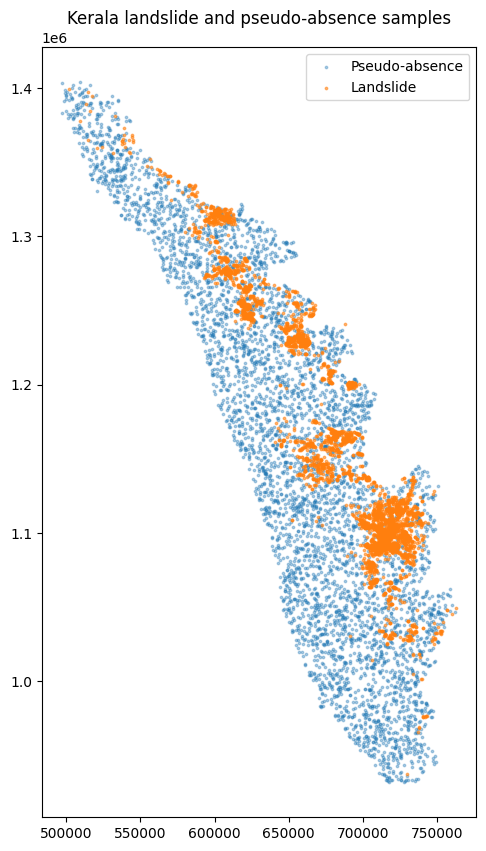

In [86]:
# 30 — Spatial distribution of landslide and pseudo-absence samples

eda_gdf = gpd.GeoDataFrame(
    eda_df.copy(),
    geometry=gpd.GeoSeries.from_wkt(eda_df["geometry"]),
    crs=TARGET_CRS
)

fig, ax = plt.subplots(figsize=(8, 10))

eda_gdf[eda_gdf["label"] == 0].plot(
    ax=ax,
    markersize=3,
    alpha=0.35,
    label="Pseudo-absence"
)

eda_gdf[eda_gdf["label"] == 1].plot(
    ax=ax,
    markersize=3,
    alpha=0.55,
    label="Landslide"
)

ax.legend()
ax.set_title("Kerala landslide and pseudo-absence samples")
plt.show()


In [88]:
# ==========================================================
# Mann–Whitney U test for continuous factors
# ==========================================================

from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np


mannwhitney_results = []


for col in continuous_factor_columns:

    group_0 = (
        eda_df.loc[
            eda_df["label"] == 0,
            col
        ]
        .dropna()
    )

    group_1 = (
        eda_df.loc[
            eda_df["label"] == 1,
            col
        ]
        .dropna()
    )


    # Mann–Whitney U test
    u_stat, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )


    # Rank-biserial correlation effect size
    n0 = len(group_0)
    n1 = len(group_1)

    rank_biserial = (
        1 - (2 * u_stat) / (n0 * n1)
    )


    mannwhitney_results.append(
        {
            "Factor": col,

            "Non-landslide median":
                group_0.median(),

            "Landslide median":
                group_1.median(),

            "U statistic":
                u_stat,

            "p-value":
                p_value,

            "Rank-biserial":
                rank_biserial,

            "Significant":
                "Yes" if p_value < 0.05 else "No"
        }
    )


mannwhitney_df = pd.DataFrame(
    mannwhitney_results
)


display(
    mannwhitney_df.round(
        {
            "Non-landslide median": 3,
            "Landslide median": 3,
            "U statistic": 2,
            "p-value": 6,
            "Rank-biserial": 3
        }
    )
)

,Factor,Non-landslide median,Landslide median,U statistic,p-value,Rank-biserial,Significant
0,elev,72.428,750.643,3312706.5,0.000000,0.703,Yes
1,aspect,187.200,174.228,12144651.0,0.000000,-0.089,Yes
2,planc,0.000,0.001,10981670.0,0.195135,0.015,No
3,profc,-0.000,0.000,10401315.0,0.000000,0.067,Yes
4,slope,5.570,26.449,1955806.0,0.000000,0.825,Yes
5,spi,9.673,51.707,4902180.0,0.000000,0.560,Yes
6,twi,6.731,5.318,17689867.0,0.000000,-0.586,Yes
7,clay,30.605,32.321,7350415.0,0.000000,0.342,Yes
8,sand,39.525,38.623,12201404.5,0.000000,-0.092,Yes
9,soc,39.263,50.201,4592041.5,0.000000,0.589,Yes


In [89]:
def interpret_rank_biserial(value):

    value = abs(value)

    if value < 0.10:
        return "Negligible"

    elif value < 0.30:
        return "Small"

    elif value < 0.50:
        return "Moderate"

    else:
        return "Large"


mannwhitney_df[
    "Effect size"
] = mannwhitney_df[
    "Rank-biserial"
].apply(
    interpret_rank_biserial
)


display(
    mannwhitney_df.round(3)
)

,Factor,Non-landslide median,Landslide median,U statistic,p-value,Rank-biserial,Significant,Effect size
0,elev,72.428,750.643,3312706.5,0.000,0.703,Yes,Large
1,aspect,187.200,174.228,12144651.0,0.000,-0.089,Yes,Negligible
2,planc,0.000,0.001,10981670.0,0.195,0.015,No,Negligible
3,profc,-0.000,0.000,10401315.0,0.000,0.067,Yes,Negligible
4,slope,5.570,26.449,1955806.0,0.000,0.825,Yes,Large
5,spi,9.673,51.707,4902180.0,0.000,0.560,Yes,Large
6,twi,6.731,5.318,17689867.0,0.000,-0.586,Yes,Large
7,clay,30.605,32.321,7350415.0,0.000,0.342,Yes,Moderate
8,sand,39.525,38.623,12201404.5,0.000,-0.092,Yes,Negligible
9,soc,39.263,50.201,4592041.5,0.000,0.589,Yes,Large


In [90]:
# ==========================================================
# Chi-square test + Cramér's V
# for categorical conditioning factors
# ==========================================================

from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np


chi_square_results = []


for col in categorical_factor_columns:

    # Remove missing values
    test_df = eda_df[
        [col, "label"]
    ].dropna()


    # Contingency table
    contingency = pd.crosstab(
        test_df[col],
        test_df["label"]
    )


    # Chi-square test
    chi2, p_value, dof, expected = (
        chi2_contingency(
            contingency
        )
    )


    # Cramér's V
    n = contingency.values.sum()

    rows, cols = (
        contingency.shape
    )

    cramers_v = np.sqrt(
        chi2 /
        (
            n
            * min(
                rows - 1,
                cols - 1
            )
        )
    )


    chi_square_results.append(
        {
            "Factor": col,

            "Chi-square":
                chi2,

            "Degrees of freedom":
                dof,

            "p-value":
                p_value,

            "Cramer's V":
                cramers_v,

            "Significant":
                "Yes"
                if p_value < 0.05
                else "No"
        }
    )


chi_square_df = pd.DataFrame(
    chi_square_results
)


display(
    chi_square_df.round(
        {
            "Chi-square": 3,
            "p-value": 6,
            "Cramer's V": 3
        }
    )
)

,Factor,Chi-square,Degrees of freedom,p-value,Cramer's V,Significant
0,landcover,538.581,7,0.0,0.239,Yes
1,geologi,894.140,7,0.0,0.311,Yes


In [91]:
def interpret_cramers_v(value):

    if value < 0.10:
        return "Negligible"

    elif value < 0.30:
        return "Small"

    elif value < 0.50:
        return "Moderate"

    else:
        return "Large"


chi_square_df[
    "Association strength"
] = chi_square_df[
    "Cramer's V"
].apply(
    interpret_cramers_v
)


display(
    chi_square_df.round(3)
)

,Factor,Chi-square,Degrees of freedom,p-value,Cramer's V,Significant,Association strength
0,landcover,538.581,7,0.0,0.239,Yes,Small
1,geologi,894.140,7,0.0,0.311,Yes,Moderate


In [92]:
# Show categorical contingency tables

for col in categorical_factor_columns:

    print(
        f"\n=============================="
        f"\n{col.upper()}"
        f"\n=============================="
    )

    table = pd.crosstab(
        eda_df[col],
        eda_df["label"],
        margins=True
    )

    display(table)


LANDCOVER


label,0,1,All
landcover,,,
10.0,4030,4226,8256
30.0,215,482,697
40.0,177,0,177
50.0,134,18,152
60.0,4,0,4
80.0,129,2,131
90.0,38,0,38
95.0,1,0,1
All,4728,4728,9456



GEOLOGI


label,0,1,All
geologi,,,
1.0,2137,1740,3877
2.0,12,7,19
3.0,2,0,2
4.0,6,0,6
5.0,1819,2971,4790
6.0,59,0,59
8.0,506,0,506
9.0,5,0,5
All,4546,4718,9264


## 14. Preprocessing for modelling

Continuous variables are standardized using training data only.

`landcover` (and optional geology) are **categorical**, so they are one-hot encoded rather than treated as continuous numbers.

The notebook saves both the raw train/test splits and the fitted preprocessing object. A later modelling notebook can compare Random Forest, XGBoost, logistic regression, etc.

> For the thesis, a random stratified split is a useful baseline. Spatial cross-validation should also be considered in the modelling stage to evaluate spatial generalization and reduce optimistic estimates caused by spatial autocorrelation.


In [94]:
# 31 — Remove rows with missing selected factors

model_df = eda_df[
    ["label"] + model_factor_columns
].copy()

print("Before dropna:", model_df.shape)

model_df = model_df.dropna(
    subset=model_factor_columns
)

print("After dropna :", model_df.shape)
print("\nClass balance:")
print(model_df["label"].value_counts())


Before dropna: (9456, 14)
After dropna : (9264, 14)

Class balance:
label
1    4718
0    4546
Name: count, dtype: int64


In [ ]:
# 32 — Report potential continuous-factor outliers- do not silently remove them

for col in continuous_factor_columns:
    q1, q3 = model_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = (
        (model_df[col] < lower) |
        (model_df[col] > upper)
    ).sum()

    print(
        f"{col:12s}: {n_outliers:,} potential outliers "
        "(IQR rule; reported only)"
    )


elev        : 38 potential outliers (IQR rule; reported only)
aspect      : 0 potential outliers (IQR rule; reported only)
planc       : 1,010 potential outliers (IQR rule; reported only)
profc       : 606 potential outliers (IQR rule; reported only)
slope       : 9 potential outliers (IQR rule; reported only)
spi         : 974 potential outliers (IQR rule; reported only)
twi         : 742 potential outliers (IQR rule; reported only)
clay        : 371 potential outliers (IQR rule; reported only)
sand        : 303 potential outliers (IQR rule; reported only)
soc         : 389 potential outliers (IQR rule; reported only)
bdod        : 364 potential outliers (IQR rule; reported only)


In [96]:
# 33 — Stratified train/test split

from sklearn.model_selection import train_test_split

X = model_df[model_factor_columns]
y = model_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test :", X_test.shape, y_test.value_counts().to_dict())


Train: (7411, 13) {1: 3774, 0: 3637}
Test : (1853, 13) {1: 944, 0: 909}


In [97]:
# 34 — Fit preprocessing on TRAIN data only

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

transformers = []

if continuous_factor_columns:
    transformers.append(
        (
            "continuous",
            StandardScaler(),
            continuous_factor_columns
        )
    )

if categorical_factor_columns:
    transformers.append(
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_factor_columns
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed train shape:", X_train_processed.shape)
print("Processed test shape :", X_test_processed.shape)

X_train_processed.head()


Processed train shape: (7411, 26)
Processed test shape : (1853, 26)


,continuous__elev,continuous__aspect,continuous__planc,continuous__profc,continuous__slope,continuous__spi,continuous__twi,continuous__clay,continuous__sand,continuous__soc,...,categorical__landcover_80.0,categorical__landcover_90.0,categorical__geologi_1.0,categorical__geologi_2.0,categorical__geologi_3.0,categorical__geologi_4.0,categorical__geologi_5.0,categorical__geologi_6.0,categorical__geologi_8.0,categorical__geologi_9.0
2653,1.487503,-0.611586,0.003012,0.288999,0.579460,-0.027557,-0.240306,1.199160,-0.712897,0.450555,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6816,-1.080179,1.627500,-0.171288,0.157796,-1.066943,-0.030822,0.047996,-0.121745,0.160699,-0.989013,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8245,-1.098834,-1.334051,-0.032436,0.343898,-1.162104,-0.030940,-0.095165,1.263131,-0.944907,1.452268,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8745,0.533875,0.408503,0.074127,-0.240701,-0.831858,-0.030224,0.200327,-0.122123,0.372719,-0.838497,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9065,-0.856031,1.845019,0.097043,0.069145,-1.129758,-0.030931,-0.144160,0.527211,-0.003564,-0.495186,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [98]:
# 35 — Save modelling-ready splits and fitted preprocessor

import joblib

# Raw splits
X_train.to_csv(PROCESSED_DIR / "X_train_raw.csv", index=False)
X_test.to_csv(PROCESSED_DIR / "X_test_raw.csv", index=False)
y_train.to_csv(PROCESSED_DIR / "y_train.csv", index=False)
y_test.to_csv(PROCESSED_DIR / "y_test.csv", index=False)

# Processed splits
X_train_processed.to_csv(
    PROCESSED_DIR / "X_train_processed.csv",
    index=False
)

X_test_processed.to_csv(
    PROCESSED_DIR / "X_test_processed.csv",
    index=False
)

joblib.dump(
    preprocessor,
    PROCESSED_DIR / "preprocessor.pkl"
)

print("Saved modelling-ready train/test data and preprocessor to:")
print(PROCESSED_DIR)


Saved modelling-ready train/test data and preprocessor to:
D:\PROJECTS\Landslide_prediction\data\processed


## Expected Outputs

After all required static source datasets are available and the notebook is executed successfully, the main outputs are:

* `kerala_landslide_master.csv` — original landslide inventory attributes with WKT geometry
* `kerala_landslide_master.gpkg` — archival spatial copy of the landslide inventory
* `kerala_pseudo_absence_points.gpkg` — generated non-landslide/pseudo-absence locations
* `training_table_kerala_extended.csv` — final modelling dataset containing landslide and non-landslide samples with conditioning factors
* `training_table_kerala_extended.parquet` — Parquet version of the final modelling dataset
* `kerala_dataset_manifest.json` — reproducibility information, factor sources, parameters, CRS, resolution, and dataset configuration
* `worldcover_2021_class_legend.csv` — ESA WorldCover class-code descriptions
* `kerala_geology_legend.csv` — GLiM geology/lithology class-code descriptions
* Raw and processed train-test datasets
* `preprocessor.pkl` — saved preprocessing pipeline for model development

### Conditioning Factor Families

**Terrain and Hydrological Factors**

* Elevation (`elev`)
* Slope (`slope`)
* Aspect (`aspect`)
* Plan curvature (`planc`)
* Profile curvature (`profc`)
* Topographic Wetness Index (`twi`)
* Stream Power Index (`spi`)

**Soil Factors — SoilGrids 2.0**

* Clay content (`clay`)
* Sand content (`sand`)
* Soil Organic Carbon (`soc`)
* Bulk density (`bdod`)

**Vegetation and Land-Cover Factor**

* ESA WorldCover 2021 land-cover class (`landcover`)

**Geological Factor**

* GLiM lithology/geology class (`geologi`)

### Final Factor Structure

The current Kerala dataset contains **13 landslide-conditioning factors**:

* **11 continuous factors:** elevation, slope, aspect, plan curvature, profile curvature, TWI, SPI, clay, sand, soil organic carbon, and bulk density
* **2 categorical factors:** land cover and geology

### Excluded Factors

Distance to river (`distriv`) and distance to road (`distroad`) were excluded from the final Kerala dataset because repeated OSM/Overpass bulk extraction was not sufficiently reliable for a reproducible state-scale workflow. No artificial or substitute values were generated for these unavailable factors.

The notebook therefore uses only conditioning factors obtained from valid and reproducible spatial data sources.

